# 🤖 Đề tài 13 — Multi-Delivery Robot (Học tăng cường dạng bảng)

Robot đi trên lưới, **lấy và giao nhiều kiện hàng**, tự quyết định thứ tự. Mọi thứ nằm trong **một notebook** và chạy được trên **Google Colab**:

| Phần | Nội dung |
|---|---|
| 1–2 | Cài đặt, mô hình MDP (state, action, reward, transition, terminal, tính Markov) |
| 3–4 | 4 map (4 setting bắt buộc) + môi trường `gymnasium.Env` tự viết, mã hóa trạng thái, kích thước state space |
| 5 | 🎮 **Trò chơi**: tự điều khiển robot bằng nút bấm |
| 6 | **Quy hoạch động**: Policy Evaluation, **Policy Iteration**, **Value Iteration** (cần biết mô hình) |
| 7 | **Monte Carlo**, **SARSA**, **Q-learning** (không cần mô hình, học từ trải nghiệm) |
| 8–9 | Huấn luyện nhiều seed, đường học, bảng so sánh, trực quan hóa policy |
| 10 | Thay đổi reward / tham số môi trường → policy thay đổi thế nào |
| 11 | Phân tích trường hợp thất bại / hội tụ chậm |
| 12 | Demo một episode bằng policy đã học + chơi cùng AI |
| 13 | Lưu kết quả, tóm tắt, gợi ý trình bày |

**Cách chạy trên Colab:** `File → Upload notebook` → chọn file này → `Runtime → Run all`. Chỉ cần CPU (không cần GPU). Toàn bộ notebook chạy khoảng **9–10 phút** trên Colab (đã thử: phần huấn luyện mất ~7 phút); đặt `QUICK = True` ở ô đầu tiên nếu chỉ muốn chạy thử nhanh (~3 phút).

> Không dùng DQN hay xấp xỉ hàm: mọi giá trị đều lưu trong **bảng** `V[s]` hoặc `Q[s, a]`.

## 1. Cài đặt thư viện

Colab đã có sẵn `numpy`, `matplotlib`, `ipywidgets`; ô dưới chỉ cài `gymnasium` nếu còn thiếu.

In [1]:
import importlib, subprocess, sys
try:
    importlib.import_module("gymnasium")
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium"], check=True)

import json, math, os, random, shutil, time
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, clear_output, display
import gymnasium as gym
from gymnasium import spaces
try:
    import ipywidgets as widgets          # nút bấm cho trò chơi (Colab có sẵn)
except ImportError:
    widgets = None

QUICK = False          # True = chạy thử nhanh (ít episode, 2 seed); False = chạy đầy đủ
SEEDS = [0, 1] if QUICK else [0, 1, 2]
OUT = "ket_qua"        # thư mục lưu hình, bảng Q, file cấu hình
os.makedirs(f"{OUT}/configs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "animation.embed_limit": 60})
IN_COLAB = "google.colab" in sys.modules
print("gymnasium", gym.__version__, "| numpy", np.__version__, "| ipywidgets:", widgets is not None,
      "| Colab:", IN_COLAB, "| QUICK:", QUICK)

gymnasium 1.3.0 | numpy 2.5.3 | ipywidgets: True | Colab: False | QUICK: False


## 2. Mô hình MDP

### 2.1 State (trạng thái)

$$s = (\text{hàng},\ \text{cột},\ \underbrace{(k_1, \dots, k_K)}_{\text{trạng thái từng kiện}},\ t,\ b)$$

| Thành phần | Giá trị | Ý nghĩa |
|---|---|---|
| hàng, cột | vị trí robot | như Taxi |
| $k_i$ | 0 = **chưa lấy**, 1 = **đang mang**, 2 = **đã giao** | mỗi kiện một chữ số |
| $t$ | 0…D | **đồng hồ deadline** (chỉ có ở map có kiện deadline) |
| $b$ | 0 = chưa dùng, 1 = **đang hiệu lực**, 2 = đã hết | **ô tăng tải** (chỉ có ở map có ô `T`) |

**Mã hóa trạng thái kiện (cơ số 3):** bộ $(k_1,\dots,k_K)$ được đọc như một số hệ cơ số 3:
$$\text{code} = \sum_{i=1}^{K} k_i \cdot 3^{\,i-1} \in \{0,\dots,3^K-1\}$$
Ví dụ 3 kiện (A = đã giao, B = đang mang, C = chưa lấy) = (2, 1, 0) → code = 2·1 + 1·3 + 0·9 = **5**.
(Cách bitmask tương đương là dùng 2 mặt nạ bit `đã_lấy` và `đã_giao` → $4^K$ tổ hợp, trong đó có tổ hợp vô nghĩa như “đã giao nhưng chưa lấy”; cơ số 3 gọn hơn: $3^K$.)

**Mã hóa cả state thành một số nguyên** (để làm chỉ số hàng trong bảng Q) — kiểu “hệ cơ số hỗn hợp”:
$$s_{id} = \big(((\text{hàng}\cdot W + \text{cột})\cdot 3^K + \text{code})\cdot n_t + t\big)\cdot n_b + b$$

**Kích thước state space:** $|S| = H \cdot W \cdot 3^K \cdot n_t \cdot n_b$, với $n_t = D+1$ nếu có deadline (ngược lại 1), $n_b = 3$ nếu có ô tăng tải (ngược lại 1). Nhiều state trong số đó không bao giờ gặp (robot trong tường, mang 2 kiện khi sức chứa 1…) nên ta báo cáo thêm **số state đạt tới được** (tìm bằng BFS từ điểm xuất phát).

### 2.2 Action (hành động) — 6 hành động như Taxi
`0 Lên · 1 Xuống · 2 Trái · 3 Phải · 4 Pickup · 5 Drop` → $|A| = 6$.

### 2.3 Transition (tất định) — thứ tự xử lý trong một bước
1. **Di chuyển**: sang ô bên cạnh nếu không phải tường/biên, ngược lại đứng yên. Bước vào ô `T` khi $b=0$ → $b=1$ (kích hoạt tăng tải).
2. **Pickup**: hợp lệ nếu đứng ở điểm lấy của một kiện *chưa lấy* và số kiện đang mang < sức chứa (sức chứa = `boost_capacity` khi $b=1$, ngược lại `capacity`). Kiện đó → *đang mang*.
3. **Drop**: hợp lệ nếu đứng ở điểm giao của một kiện *đang mang*. Kiện đó → *đã giao*. Nếu $b=1$ thì $b \to 2$: **tăng tải chỉ có hiệu lực cho một chuyến** (hết ngay ở lần giao đầu tiên sau khi kích hoạt).
4. **Đồng hồ deadline**: nếu kiện deadline chưa giao thì $t \leftarrow \min(t+1, D)$; đúng lúc $t$ chạm $D$ mà chưa giao → phạt trễ một lần. Khi kiện deadline đã giao, đặt $t = D$ (thời gian không còn ảnh hưởng tương lai → gộp state cho gọn).

### 2.4 Reward
| Sự kiện | Reward mặc định |
|---|---|
| mỗi bước | −1 (khuyến khích đường ngắn) |
| giao đúng một kiện | +20 (có thể đặt riêng cho **đơn ưu tiên**, vd. +50) |
| Pickup / Drop sai chỗ | −10 |
| kiện deadline trễ hạn | −`late` (phạt một lần) |

### 2.5 Terminal và truncation
- **Terminal**: tất cả kiện ở trạng thái *đã giao*.
- **Truncation**: hết `max_steps` bước (chỉ là giới hạn để episode không dài vô hạn khi huấn luyện, **không** phải một phần của bài toán ⇒ thuật toán TD vẫn bootstrap ở bước bị cắt).

### 2.6 Vì sao cần thêm $t$ và $b$ (tính Markov)?
Tính Markov: *tương lai chỉ phụ thuộc vào state hiện tại*, không phụ thuộc lịch sử.
- Nếu thiếu $t$: hai lần robot đứng cùng ô, cùng trạng thái kiện nhưng ở bước 3 và bước 13 sẽ trông giống hệt nhau, dù một lần còn kịp deadline, một lần đã trễ → reward tương lai khác nhau → **không Markov**.
- Nếu thiếu $b$: không biết robot đã dùng ô tăng tải chưa / còn hiệu lực không → không biết Pickup kiện thứ 2 có hợp lệ không → **không Markov**.
- Bộ đếm `steps` dùng cho `max_steps` **không** nằm trong state vì nó không thuộc bài toán (chỉ là giới hạn huấn luyện).

## 3. Bốn map (4 setting bắt buộc) — độ khó tăng dần

Ký hiệu trong map: `S` xuất phát · `#` tường · `.` ô trống · **chữ HOA** = điểm lấy kiện · **chữ thường** = điểm giao của kiện đó · `T` = ô tăng tải.

| Map | Setting | Ràng buộc |
|---|---|---|
| L1 | 1. 2 kiện độc lập | mang được cả 2 cùng lúc |
| L2 | 2. 3 kiện, chỉ mang 1 | phải đi từng chuyến, thứ tự quan trọng |
| L3 | 3. một kiện có deadline | thêm đồng hồ $t$ vào state |
| L4 | 4. ô tăng tải | mang được 2 kiện, **chỉ một chuyến**; thêm $b$ vào state |

Các map được lưu ra `ket_qua/configs/*.json` (file cấu hình/map).

In [2]:
BASE_REWARD = {"step": -1, "deliver": 20, "illegal": -10, "late": 0}

MAPS = {
    "L1": dict(
        title="L1 · 2 kiện độc lập (mang được 2)",
        grid=["S . A . .",
              ". # # # .",
              ". . B . .",
              ". # . # .",
              ". . . b a"],
        capacity=2, rewards=dict(BASE_REWARD), max_steps=100),
    "L2": dict(
        title="L2 · 3 kiện, chỉ mang được 1",
        grid=["S . . # . A",
              ". # . . . .",
              ". # c # # .",
              ". . . . . .",
              "B # # . # b",
              ". . a . . C"],
        capacity=1, rewards=dict(BASE_REWARD), max_steps=150),
    "L3": dict(
        title="L3 · 3 kiện, kiện C có deadline",
        grid=["S . A . . .",
              ". # # # # .",
              "a . . . b .",
              ". # # # # .",
              "B . . . # .",
              "c # . . . C"],
        capacity=1, deadline={"C": 22}, rewards=dict(BASE_REWARD, late=30), max_steps=150),
    "L4": dict(
        title="L4 · 4 kiện + ô tăng tải T (mang 2, một chuyến)",
        grid=["S . . # . . .",
              ". # . . . # D",
              ". # T # . . .",
              "A . B . # c .",
              ". # # . . # .",
              ". . . # . a b",
              "d . . . . # C"],
        capacity=1, boost_capacity=2, rewards=dict(BASE_REWARD), max_steps=250),
}

for name, cfg in MAPS.items():
    with open(f"{OUT}/configs/{name}.json", "w", encoding="utf-8") as f:
        json.dump(cfg, f, ensure_ascii=False, indent=2)
print("Đã lưu cấu hình:", sorted(os.listdir(f"{OUT}/configs")))

Đã lưu cấu hình: ['L1.json', 'L2.json', 'L3.json', 'L4.json']


## 4. Môi trường `MultiDeliveryEnv` (custom `gymnasium.Env`, phát triển từ logic Taxi)

- `transition(state, action)` là **luật chơi duy nhất** (mục 2.3). Mọi thứ khác đều gọi nó.
- Vì môi trường **tất định**, ta lập sẵn bảng mô hình cho mọi state: `NS[s,a]` (state kế tiếp), `R[s,a]` (reward), `TERM[s,a]` (kết thúc?). Tức là $P(s' \mid s,a) = 1$ với đúng một $s' =$ `NS[s,a]`.
  - **Quy hoạch động** (mục 6) đọc trực tiếp bảng này (vì DP *cần biết mô hình*).
  - **MC / SARSA / Q-learning** (mục 7) *không* nhìn bảng, chỉ gọi `reset()` / `step()` như một agent thật.

In [3]:
# Hành động (giống Taxi-v3)
UP, DOWN, LEFT, RIGHT, PICKUP, DROP = range(6)
ACTION_NAMES = ["Lên", "Xuống", "Trái", "Phải", "Pickup", "Drop"]
ARROWS = ["↑", "↓", "←", "→", "P", "D"]
MOVES = {UP: (-1, 0), DOWN: (1, 0), LEFT: (0, -1), RIGHT: (0, 1)}

# Trạng thái của MỘT kiện hàng
WAIT, CARRY, DONE = 0, 1, 2
STATUS_NAMES = ["chưa lấy", "đang mang", "đã giao"]
BOOST_NAMES = ["chưa dùng", "đang hiệu lực", "đã hết"]


class MultiDeliveryEnv(gym.Env):
    """Robot giao nhiều kiện. State = (hàng, cột, (k_1..k_K), t, b) — xem mục 2.1."""
    metadata = {"render_modes": ["ansi"]}

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.title = cfg.get("title", "")
        # --- đọc map ---
        self.grid = [row.replace(" ", "") for row in cfg["grid"]]
        self.H, self.W = len(self.grid), len(self.grid[0])
        self.walls, pick, drop = set(), {}, {}
        self.start = self.booster = None
        for r, row in enumerate(self.grid):
            assert len(row) == self.W, "các dòng của map phải dài bằng nhau"
            for c, ch in enumerate(row):
                if ch == "#":
                    self.walls.add((r, c))
                elif ch == "S":
                    self.start = (r, c)
                elif ch == "T":
                    self.booster = (r, c)
                elif ch.isupper():
                    pick[ch] = (r, c)
                elif ch.islower():
                    drop[ch.upper()] = (r, c)
        assert set(pick) == set(drop), "mỗi kiện cần 1 điểm lấy (HOA) và 1 điểm giao (thường)"
        self.names = sorted(pick)                      # ["A", "B", "C", ...]
        self.K = len(self.names)
        self.pick_pos = [pick[n] for n in self.names]
        self.drop_pos = [drop[n] for n in self.names]
        self.capacity = cfg.get("capacity", 1)
        self.boost_capacity = cfg.get("boost_capacity", 2)
        # --- reward ---
        rw = cfg["rewards"]
        self.r_step, self.r_illegal, self.r_late = rw["step"], rw["illegal"], rw.get("late", 0)
        prio = rw.get("priority", {})                  # đơn ưu tiên, vd. {"A": 50}
        self.r_deliver = [prio.get(n, rw["deliver"]) for n in self.names]
        # --- deadline (tối đa 1 kiện) ---
        dl = cfg.get("deadline", {})                   # vd. {"C": 12}
        assert len(dl) <= 1, "notebook này hỗ trợ tối đa 1 kiện có deadline"
        self.dl = self.names.index(next(iter(dl))) if dl else None
        self.D = next(iter(dl.values())) if dl else 0
        self.max_steps = cfg["max_steps"]
        # --- kích thước state space: |S| = H·W · 3^K · n_t · n_b ---
        self.n_pos = self.H * self.W
        self.n_pkg = 3 ** self.K
        self.n_time = self.D + 1 if self.dl is not None else 1
        self.n_boost = 3 if self.booster else 1
        self.nS = self.n_pos * self.n_pkg * self.n_time * self.n_boost
        self.nA = 6
        self.observation_space = spaces.Discrete(self.nS)
        self.action_space = spaces.Discrete(self.nA)
        self.s0 = self.encode(*self.start, (WAIT,) * self.K, 0, 0)
        self._build_model()
        self._start_pool = None                       # cho exploring starts (tính lười)
        self.s, self.steps = self.s0, 0

    # ---------- mã hóa / giải mã state ----------
    def encode(self, r, c, pkgs, t=0, b=0):
        code = sum(k * 3 ** i for i, k in enumerate(pkgs))          # trạng thái kiện: số cơ số 3
        return (((r * self.W + c) * self.n_pkg + code) * self.n_time + t) * self.n_boost + b

    def decode(self, s):
        s, b = divmod(s, self.n_boost)
        s, t = divmod(s, self.n_time)
        pos, code = divmod(s, self.n_pkg)
        r, c = divmod(pos, self.W)
        pkgs = []
        for _ in range(self.K):
            code, k = divmod(code, 3)
            pkgs.append(k)
        return r, c, tuple(pkgs), t, b

    # ---------- LUẬT CHƠI ----------
    def transition(self, state, a):
        """(state, action) -> (state kế tiếp, reward, terminated, mô tả sự kiện)."""
        r, c, pkgs, t, b = state
        pkgs = list(pkgs)
        reward, event = self.r_step, ""
        if a in MOVES:                                              # 1) di chuyển
            nr, nc = r + MOVES[a][0], c + MOVES[a][1]
            if 0 <= nr < self.H and 0 <= nc < self.W and (nr, nc) not in self.walls:
                r, c = nr, nc                                       # đâm tường/biên -> đứng yên
            if (r, c) == self.booster and b == 0:
                b, event = 1, "kích hoạt ô tăng tải"
        elif a == PICKUP:                                           # 2) lấy hàng
            cap = self.boost_capacity if b == 1 else self.capacity
            i = self._parcel_at((r, c), self.pick_pos, pkgs, WAIT)
            if i is not None and pkgs.count(CARRY) < cap:
                pkgs[i], event = CARRY, f"lấy kiện {self.names[i]}"
            else:
                reward, event = reward + self.r_illegal, "Pickup sai"
        else:                                                       # 3) giao hàng
            i = self._parcel_at((r, c), self.drop_pos, pkgs, CARRY)
            if i is not None:
                pkgs[i] = DONE
                reward += self.r_deliver[i]
                event = f"giao kiện {self.names[i]}"
                if b == 1:
                    b = 2                                           # tăng tải chỉ dùng cho 1 chuyến
            else:
                reward, event = reward + self.r_illegal, "Drop sai"
        if self.dl is not None:                                     # 4) đồng hồ deadline
            if pkgs[self.dl] == DONE:
                t = self.D                                          # đã giao -> gộp thời gian
            elif t < self.D:
                t += 1
                if t == self.D:                                     # vừa hết hạn mà chưa giao
                    reward -= self.r_late
                    event = (event + " · trễ deadline!").strip(" ·")
        terminated = all(k == DONE for k in pkgs)
        return (r, c, tuple(pkgs), t, b), reward, terminated, event

    def _parcel_at(self, pos, positions, pkgs, need):
        for i, p in enumerate(positions):
            if p == pos and pkgs[i] == need:
                return i
        return None

    # ---------- bảng mô hình (dùng cho DP) ----------
    def _build_model(self):
        nS = self.nS
        self.NS = np.tile(np.arange(nS)[:, None], (1, self.nA))  # mặc định đứng yên (state kết thúc/ô tường)
        self.R = np.zeros((nS, self.nA))
        self.TERM = np.zeros((nS, self.nA), dtype=bool)
        self.is_terminal = np.zeros(nS, dtype=bool)
        self.valid = np.zeros(nS, dtype=bool)                     # False = robot nằm trong tường
        for s in range(nS):
            st = self.decode(s)
            if (st[0], st[1]) in self.walls:
                continue
            self.valid[s] = True
            if all(k == DONE for k in st[2]):
                self.is_terminal[s] = True
                continue
            for a in range(self.nA):
                st2, rew, term, _ = self.transition(st, a)
                self.NS[s, a], self.R[s, a], self.TERM[s, a] = self.encode(*st2), rew, term
        # bản list Python: step() tra list nhanh hơn tra numpy trong vòng lặp huấn luyện
        self._ns, self._r, self._term = self.NS.tolist(), self.R.tolist(), self.TERM.tolist()

    def reachable_states(self):
        """BFS từ điểm xuất phát -> các state thật sự có thể gặp."""
        seen, queue = {self.s0}, deque([self.s0])
        while queue:
            s = queue.popleft()
            if self.is_terminal[s]:
                continue
            for a in range(self.nA):
                s2 = self._ns[s][a]
                if s2 not in seen:
                    seen.add(s2)
                    queue.append(s2)
        return np.array(sorted(seen))

    # ---------- API gymnasium ----------
    def reset(self, seed=None, options=None):
        """options: {"state": s} = bắt đầu ở state s; {"random_start": True} = state ngẫu nhiên
        (trong các state đạt tới được, chưa kết thúc) — giống Taxi-v3 vốn xuất phát ngẫu nhiên."""
        super().reset(seed=seed)
        options = options or {}
        if "state" in options:
            self.s = int(options["state"])
        elif options.get("random_start"):
            if self._start_pool is None:
                reach = self.reachable_states()
                self._start_pool = reach[~self.is_terminal[reach]]
            self.s = int(self._start_pool[self.np_random.integers(len(self._start_pool))])
        else:
            self.s = self.s0                          # mặc định: ô S, mọi kiện chưa lấy
        self.steps = 0
        return self.s, {}

    def step(self, a):
        s = self.s
        self.s = self._ns[s][a]
        self.steps += 1
        term = self._term[s][a]
        trunc = (not term) and self.steps >= self.max_steps
        return self.s, self._r[s][a], term, trunc, {}

    def event(self, s, a):
        """Mô tả bằng chữ chuyện gì xảy ra khi làm action a ở state s (dùng cho demo/trò chơi)."""
        return self.transition(self.decode(s), a)[3]

    def describe(self, s):
        r, c, pkgs, t, b = self.decode(s)
        parts = [f"robot ({r},{c})"] + [f"{n}: {STATUS_NAMES[k]}" for n, k in zip(self.names, pkgs)]
        if self.dl is not None:
            parts.append(f"deadline {self.names[self.dl]}: t={t}/{self.D}")
        if self.booster:
            parts.append(f"tăng tải: {BOOST_NAMES[b]}")
        return " | ".join(parts)

    def render(self):
        r0, c0, pkgs, t, b = self.decode(self.s)
        rows = []
        for r in range(self.H):
            row = []
            for c in range(self.W):
                ch = "#" if (r, c) in self.walls else "."
                if (r, c) == self.start:
                    ch = "S"
                if (r, c) == self.booster:
                    ch = "T" if b == 0 else "t"
                for i, n in enumerate(self.names):
                    if self.drop_pos[i] == (r, c):
                        ch = "✓" if pkgs[i] == DONE else n.lower()
                    if self.pick_pos[i] == (r, c) and pkgs[i] == WAIT:
                        ch = n
                row.append("@" if (r, c) == (r0, c0) else ch)
            rows.append(" ".join(row))
        return "\n".join(rows) + "\n" + self.describe(self.s)


ENVS = {name: MultiDeliveryEnv(cfg) for name, cfg in MAPS.items()}
print(ENVS["L2"].render())

@ . . # . A
. # . . . .
. # c # # .
. . . . . .
B # # . # b
. . a . . C
robot (0,0) | A: chưa lấy | B: chưa lấy | C: chưa lấy


### 4.1 Kiểm tra nhanh luật chơi

Vài phép thử tự động để chắc chắn môi trường đúng như mô tả (mã hóa ↔ giải mã, sức chứa, tăng tải một chuyến, deadline).

In [4]:
env = ENVS["L4"]
# 1) encode/decode là hai phép ngược nhau
for s in np.random.default_rng(0).integers(env.nS, size=2000):
    assert env.encode(*env.decode(int(s))) == s
# 2) ví dụ mã hóa trạng thái kiện ở mục 2.1: (2, 1, 0) -> 5
assert sum(k * 3 ** i for i, k in enumerate((2, 1, 0))) == 5

# 3) sức chứa 1: đang mang A thì không lấy được thêm (nếu chưa tăng tải)
rA, cA = env.pick_pos[0]
rB, cB = env.pick_pos[1]
st = (rB, cB, (CARRY, WAIT, WAIT, WAIT), 0, 0)
assert env.transition(st, PICKUP)[3] == "Pickup sai"
# 4) đang tăng tải (b=1): lấy được kiện thứ 2
st2, _, _, ev = env.transition((rB, cB, (CARRY, WAIT, WAIT, WAIT), 0, 1), PICKUP)
assert ev == "lấy kiện B" and st2[2][:2] == (CARRY, CARRY)
# 5) giao kiện đầu tiên -> tăng tải hết hiệu lực (b: 1 -> 2)
ra, ca = env.drop_pos[0]
st3, rew, _, ev = env.transition((ra, ca, (CARRY, CARRY, WAIT, WAIT), 0, 1), DROP)
assert ev == "giao kiện A" and st3[4] == 2 and rew == -1 + 20

# 6) deadline: đồng hồ dừng ở D, phạt đúng một lần
env3 = ENVS["L3"]
state, total_late = env3.decode(env3.s0), 0
for k in range(env3.D + 5):
    state, rew, _, ev = env3.transition(state, LEFT)   # đứng yên ở góc, không giao
    total_late += "trễ" in ev
assert state[3] == env3.D and total_late == 1

# 7) step() của gymnasium khớp với luật chơi transition()
env.reset(seed=0)
for _ in range(300):
    s = env.s
    a = int(env.action_space.sample())
    st2, rew, term, _ = env.transition(env.decode(s), a)
    s2, r2, term2, trunc2, _ = env.step(a)
    assert (s2, r2, term2) == (env.encode(*st2), rew, term)
    if term2 or trunc2:
        env.reset(options={"random_start": True})
print("✅ Tất cả kiểm tra luật chơi đều đúng")

✅ Tất cả kiểm tra luật chơi đều đúng


### 4.2 Kích thước state space và action space

In [5]:
def map_table():
    rows = []
    for name, env in ENVS.items():
        reach = env.reachable_states()
        rows.append(dict(map=name, luoi=f"{env.H}x{env.W}", K=env.K, suc_chua=env.capacity,
                         deadline=f"{env.names[env.dl]}≤{env.D}" if env.dl is not None else "—",
                         tang_tai="có" if env.booster else "—",
                         cong_thuc=f"{env.H*env.W}·3^{env.K}·{env.n_time}·{env.n_boost}",
                         S=env.nS, S_dat_toi=len(reach), A=env.nA))
    return rows

STATE_TABLE = map_table()
print(f"{'map':4} {'lưới':5} {'K':>2} {'chứa':>4} {'deadline':>8} {'tăng tải':>8} "
      f"{'công thức |S|':>16} {'|S|':>7} {'đạt tới':>8} {'|A|':>4}")
for r in STATE_TABLE:
    print(f"{r['map']:4} {r['luoi']:5} {r['K']:>2} {r['suc_chua']:>4} {r['deadline']:>8} {r['tang_tai']:>8} "
          f"{r['cong_thuc']:>16} {r['S']:>7,} {r['S_dat_toi']:>8,} {r['A']:>4}")

map  lưới   K chứa deadline tăng tải    công thức |S|     |S|  đạt tới  |A|
L1   5x5    2    2        —        —       25·3^2·1·1     225      162    6
L2   6x6    3    1        —        —       36·3^3·1·1     972      535    6
L3   6x6    3    1     C≤22        —      36·3^3·23·1  22,356    2,425    6
L4   7x7    4    1        —       có       49·3^4·1·3  11,907    6,041    6


### 4.3 Vẽ map

Ký hiệu trên hình: ⚫ robot · ô màu đặc có chữ HOA = kiện đang chờ ở điểm lấy · ô viền nét đứt có chữ thường = điểm giao (✓ khi đã giao) · ô vàng `T ×2` = ô tăng tải · ô vuông nhỏ trên robot = kiện đang mang.

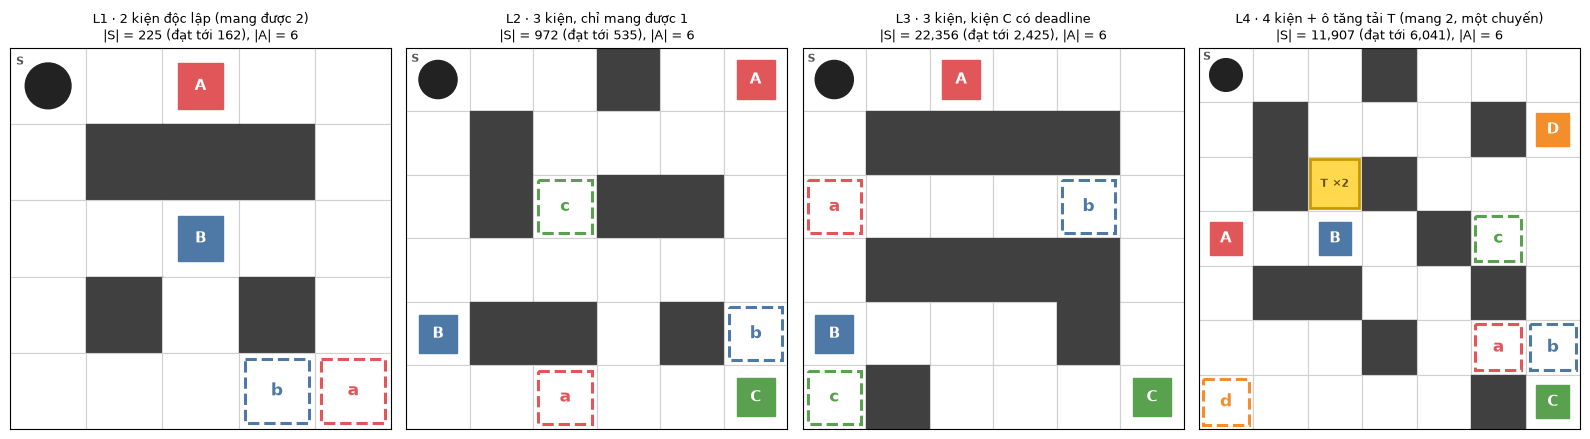

In [6]:
PCOL = ["#e15759", "#4e79a7", "#59a14f", "#f28e2b", "#b07aa1", "#76b7b2"]   # màu của kiện A, B, C, D...
SHORT = ["chờ", "mang", "xong"]


def draw_state(env, s, ax=None, title=None, values=None, arrows=None, wrong=None, path=None):
    """Vẽ map ở state s.
    values: mảng H×W tô nền (vd. V*) · arrows: H×W ký hiệu action · wrong: H×W True = action sai
    path: danh sách ô (hàng, cột) robot đi qua."""
    if ax is None:
        _, ax = plt.subplots(figsize=(0.65 * env.W + 1.2, 0.65 * env.H + 1.0))
    r0, c0, pkgs, t, b = env.decode(s)
    H, W = env.H, env.W
    small = arrows is not None                      # có mũi tên -> ký hiệu kiện vẽ nhỏ ở góc ô
    if values is not None:
        ax.imshow(np.ma.masked_invalid(values), cmap="Blues", extent=(-.5, W - .5, H - .5, -.5))
    for r in range(H):
        for c in range(W):
            if (r, c) in env.walls:
                ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="#404040"))
            elif values is None:
                ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fc="white", ec="#d0d0d0", lw=.8))
    sr, sc = env.start
    ax.text(sc - .42, sr - .28, "S", fontsize=8, color="#555", fontweight="bold")
    if env.booster:
        br, bc = env.booster
        ax.add_patch(plt.Rectangle((bc - .45, br - .45), .9, .9, fc="#ffd84d" if b == 0 else "#eeeeee",
                                   ec="#c99a00", lw=2, alpha=.45 if small else 1))
        if not small:
            ax.text(bc, br, ["T ×2", "ON", "hết"][b], ha="center", va="center", fontsize=8,
                    fontweight="bold", color="#6b5200")
    for i, n in enumerate(env.names):
        col = PCOL[i % len(PCOL)]
        (pr, pc), (dr, dc) = env.pick_pos[i], env.drop_pos[i]
        done = pkgs[i] == DONE
        ax.add_patch(plt.Rectangle((dc - .42, dr - .42), .84, .84, fill=done, fc=col,
                                   alpha=.35 if done else 1, ec=col, lw=2.2, ls="--"))
        if small:
            ax.text(dc + .4, dr - .4, n.lower(), ha="right", va="top", color=col, fontsize=8, fontweight="bold")
        else:
            ax.text(dc, dr, "✓" if done else n.lower(), ha="center", va="center", color=col,
                    fontsize=12, fontweight="bold")
        if pkgs[i] == WAIT:
            if small:
                ax.add_patch(plt.Rectangle((pc - .45, pr - .45), .28, .28, color=col))
            else:
                ax.add_patch(plt.Rectangle((pc - .3, pr - .3), .6, .6, color=col))
                ax.text(pc, pr, n, ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    if path:
        ax.plot([c for _, c in path], [r for r, _ in path], "-", color="#ff7f0e", lw=3, alpha=.55, zorder=3)
    if arrows is not None:
        for r in range(H):
            for c in range(W):
                if arrows[r][c]:
                    bad = wrong is not None and wrong[r][c]
                    ax.text(c, r, arrows[r][c], ha="center", va="center", zorder=4,
                            fontsize=12 if arrows[r][c] in "↑↓←→" else 9, fontweight="bold",
                            color="#d62728" if bad else "#111111")
    else:
        ax.add_patch(plt.Circle((c0, r0), .3, color="#222222", zorder=5))
        carried = [i for i, k in enumerate(pkgs) if k == CARRY]
        x = c0 - (0.2 * len(carried) + 0.04 * (len(carried) - 1)) / 2
        for i in carried:
            ax.add_patch(plt.Rectangle((x, r0 - .1), .2, .2, color=PCOL[i % len(PCOL)], zorder=6))
            x += .24
    ax.set_xlim(-.5, W - .5)
    ax.set_ylim(H - .5, -.5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)
    return ax


fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, (name, env) in zip(axes, ENVS.items()):
    draw_state(env, env.s0, ax, title=f"{env.title}\n|S| = {env.nS:,} (đạt tới {len(env.reachable_states()):,}), |A| = 6")
plt.tight_layout(); plt.savefig(f"{OUT}/maps.png", dpi=120); plt.show()

## 5. 🎮 Trò chơi: tự điều khiển robot

Bấm các nút để di chuyển, **Pickup** để lấy kiện, **Drop** để giao. Ô thông tin bên phải hiện reward từng bước. Đổi map bằng ô *Map*.

Sau khi chạy mục 6–8, ở **mục 12** có thêm nút **🤖 AI** để xem policy đã học (Value Iteration, Q-learning, SARSA, Monte Carlo) đi tiếp từ chỗ bạn đang đứng.
*(Nếu môi trường không có `ipywidgets`, gọi `play_text("L1")` để chơi bằng bàn phím: w/a/s/d, j = Pickup, k = Drop.)*

In [7]:
class DeliveryGame:
    """Trò chơi điều khiển robot bằng nút bấm (ipywidgets — chạy được trên Colab)."""

    def __init__(self, map_name="L1", policies=None):
        self.policies = policies or {}               # {map: {tên policy: mảng action theo state}}
        self.envs = {}                               # mỗi trò chơi có env riêng, không đụng ENVS
        W = widgets
        self.map_dd = W.Dropdown(options=list(MAPS), value=map_name, description="Map",
                                 layout=W.Layout(width="150px"))
        self.ai_dd = W.Dropdown(description="AI", layout=W.Layout(width="280px"))

        def button(text, width="62px", style=""):
            return W.Button(description=text, layout=W.Layout(width=width), button_style=style)

        moves = {UP: button("↑"), DOWN: button("↓"), LEFT: button("←"), RIGHT: button("→"),
                 PICKUP: button("Pickup", "92px", "info"), DROP: button("Drop", "92px", "info")}
        for a, btn in moves.items():
            btn.on_click(lambda _, a=a: self.act(a))
        b_ai, b_run = button("🤖 AI 1 bước", "125px", "warning"), button("🤖 AI chạy hết", "125px", "warning")
        b_reset = button("↺ Chơi lại", "125px", "danger")
        b_ai.on_click(self.ai_step)
        b_run.on_click(self.ai_run)
        b_reset.on_click(self.reset)
        self.map_dd.observe(lambda change: self.reset(), names="value")

        def pad():
            return W.Box(layout=W.Layout(width="62px"))

        dpad = W.VBox([W.HBox([pad(), moves[UP], pad()]), W.HBox([moves[LEFT], moves[DOWN], moves[RIGHT]])])
        self.out, self.info = W.Output(), W.HTML()
        self.ui = W.VBox([W.HBox([self.map_dd, self.ai_dd]),
                          W.HBox([dpad, W.VBox([moves[PICKUP], moves[DROP]]), W.VBox([b_ai, b_run, b_reset])]),
                          W.HBox([self.out, self.info])])
        self.reset()

    def reset(self, *_):
        name = self.map_dd.value
        if name not in self.envs:
            self.envs[name] = MultiDeliveryEnv(MAPS[name])
        self.env = self.envs[name]
        self.s, _ = self.env.reset()
        self.G, self.n, self.done, self.log = 0.0, 0, False, []
        names = list(self.policies.get(name, {}))
        self.ai_dd.options = names or ["(chưa có — xem mục 12)"]
        self.draw()

    def act(self, a):
        if self.done:
            return
        ev = self.env.event(self.s, a)
        self.s, r, term, trunc, _ = self.env.step(a)
        self.G += r
        self.n += 1
        self.done = term or trunc
        self.log.append(f"{self.n:>3}. {ACTION_NAMES[a]:<6} {r:+4.0f}  {ev}")
        self.draw()

    def _policy(self):
        return self.policies.get(self.map_dd.value, {}).get(self.ai_dd.value)

    def ai_step(self, *_):
        pi = self._policy()
        if pi is None:
            self.log.append("⚠ chưa có policy cho map này")
            return self.draw()
        self.act(int(pi[self.s]))

    def ai_run(self, *_):
        pi = self._policy()
        while pi is not None and not self.done:
            self.act(int(pi[self.s]))
            time.sleep(0.15)

    def draw(self):
        env = self.env
        with self.out:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(0.6 * env.W + 1, 0.6 * env.H + 0.8))
            draw_state(env, self.s, ax)
            plt.show()
        msg = ""
        if self.done:
            delivered = all(k == DONE for k in env.decode(self.s)[2])
            msg = "<b>🎉 Giao xong hết!</b>" if delivered else "<b>⏰ Hết số bước cho phép</b>"
            opt = globals().get("OPT", {}).get(self.map_dd.value)
            if opt:
                msg += f"<br>Tối ưu (Value Iteration): {opt['n']} bước, return {opt['G']:+.0f}"
        status = env.describe(self.s).replace(" | ", "<br>")
        log = "<br>".join(self.log[-10:])
        self.info.value = (f"<div style='font-family:monospace;min-width:340px;padding-left:12px'>"
                           f"<b>Bước:</b> {self.n} &nbsp; <b>Tổng reward:</b> {self.G:+.0f}<br>{status}"
                           f"<br>{msg}<hr style='margin:4px 0'>{log}</div>")


def play_text(map_name="L1"):
    """Bản chơi bằng bàn phím (khi không có ipywidgets): w/a/s/d, j = Pickup, k = Drop, q = thoát."""
    keys = {"w": UP, "s": DOWN, "a": LEFT, "d": RIGHT, "j": PICKUP, "k": DROP}
    env = MultiDeliveryEnv(MAPS[map_name])
    s, _ = env.reset()
    G = 0.0
    while True:
        print(env.render())
        k = input("w/a/s/d = đi, j = Pickup, k = Drop, q = thoát: ").strip().lower()
        if k == "q":
            break
        if k not in keys:
            continue
        ev = env.event(s, keys[k])
        s, r, term, trunc, _ = env.step(keys[k])
        G += r
        print(f"reward {r:+.0f} {ev} | tổng {G:+.0f}")
        if term or trunc:
            print(env.render())
            print("🎉 Giao xong!" if term else "Hết số bước")
            break

In [ ]:
if widgets is not None:
    game = DeliveryGame("L1")
    display(game.ui)
else:
    print("Không có ipywidgets -> chạy play_text('L1') để chơi bằng bàn phím")

## 6. Quy hoạch động (Dynamic Programming) — cần biết mô hình

DP dùng trực tiếp bảng mô hình `NS, R, TERM`. Vì môi trường tất định nên tổng theo $s'$ chỉ còn một số hạng ($s' = $ `NS[s,a]`):

$$Q(s,a) = R(s,a) + \gamma \cdot V(s') \cdot [\text{chưa kết thúc}]$$

Hàm `q_from_v` dưới đây tính công thức này cho **mọi** $(s,a)$ cùng lúc bằng numpy — đó là **một lượt cập nhật Bellman** (một *sweep*).

| Thuật toán | Công thức lặp | Ý tưởng |
|---|---|---|
| **Policy Evaluation** | $V_{k+1}(s) = R(s,\pi(s)) + \gamma V_k(s')$ | tính giá trị của một policy **cố định** |
| **Policy Iteration** | đánh giá $\pi$ → cải thiện $\pi'(s) = \arg\max_a Q^{\pi}(s,a)$ → lặp | ít vòng lặp lớn, mỗi vòng tốn một lần đánh giá |
| **Value Iteration** | $V_{k+1}(s) = \max_a \big[R(s,a) + \gamma V_k(s')\big]$ | gộp đánh giá + cải thiện vào một bước |

Dừng khi thay đổi lớn nhất $\max_s |V_{k+1}(s) - V_k(s)| < \theta$. Kết quả: $V^*$, $Q^*$ và policy tối ưu $\pi^*(s) = \arg\max_a Q^*(s,a)$ — dùng làm **chuẩn đáp án** để chấm các thuật toán học ở mục 7.

In [9]:
GAMMA = 0.99

def q_from_v(env, V, gamma=GAMMA):
    """Một lượt Bellman cho MỌI (s, a): Q = R + γ·V(s')·[chưa kết thúc]."""
    return env.R + gamma * V[env.NS] * (~env.TERM)


def policy_evaluation(env, pi, gamma=GAMMA, theta=1e-6):
    """Tính V^π của policy cố định π (π[s] = action) bằng cách lặp phương trình Bellman kỳ vọng."""
    idx = np.arange(env.nS)
    ns, r, term = env.NS[idx, pi], env.R[idx, pi], env.TERM[idx, pi]   # chỉ giữ action của π
    V = np.zeros(env.nS)
    sweeps = 0
    while True:
        sweeps += 1
        V_new = r + gamma * V[ns] * (~term)
        delta = np.abs(V_new - V).max()
        V = V_new
        if delta < theta:
            return V, sweeps


def policy_iteration(env, gamma=GAMMA, theta=1e-6):
    pi = np.zeros(env.nS, dtype=int)            # policy ban đầu: luôn đi "Lên" (rất tệ)
    idx = np.arange(env.nS)
    history = []
    while True:
        V, sweeps = policy_evaluation(env, pi, gamma, theta)           # 1) ĐÁNH GIÁ
        Q = q_from_v(env, V, gamma)
        best = Q.argmax(axis=1)                                         # 2) CẢI THIỆN (tham lam)
        better = Q[idx, best] > Q[idx, pi] + 1e-9                       # chỉ đổi khi tốt hơn thật sự
        history.append(dict(V_start=V[env.s0], sweeps=sweeps, changed=int(better.sum())))
        if not better.any():                                           # policy ổn định -> tối ưu
            return pi, V, history
        pi = np.where(better, best, pi)


def value_iteration(env, gamma=GAMMA, theta=1e-6):
    V = np.zeros(env.nS)
    deltas, v_start = [], []
    while True:
        V_new = q_from_v(env, V, gamma).max(axis=1)                     # Bellman tối ưu
        deltas.append(np.abs(V_new - V).max())
        V = V_new
        v_start.append(V[env.s0])
        if deltas[-1] < theta:
            break
    Q = q_from_v(env, V, gamma)
    return Q.argmax(axis=1), V, Q, dict(deltas=deltas, v_start=v_start)


def rollout(env, pi, start=None):
    """Chạy policy tham lam pi (mảng action theo state) từ điểm xuất phát."""
    s, _ = env.reset(options=None if start is None else {"state": start})
    steps = []
    while True:
        a = int(pi[s])
        ev = env.event(s, a)
        s2, r, term, trunc, _ = env.step(a)
        steps.append(dict(s=s, a=a, r=r, s2=s2, event=ev))
        s = s2
        if term or trunc:
            return steps, term


def route_text(steps):
    """Tóm tắt lộ trình: các sự kiện quan trọng kèm số bước."""
    evs = [f"{e['event']} (bước {k + 1})" for k, e in enumerate(steps) if e["event"]]
    return " → ".join(evs)


def order_text(steps):
    """Thứ tự giao các kiện, vd. 'C → B → A'."""
    return " → ".join(e["event"].split()[2] for e in steps if e["event"].startswith("giao kiện"))

### 6.1 Ví dụ nhỏ trên L1: xem từng thuật toán chạy ra sao

In [10]:
env = ENVS["L1"]

# (a) Policy Evaluation của một policy NGẪU NHIÊN cố định -> V^π rất thấp
rng = np.random.default_rng(0)
pi_rand = rng.integers(6, size=env.nS)
V_rand, sw = policy_evaluation(env, pi_rand)
print(f"(a) Policy ngẫu nhiên cố định: V^π(start) = {V_rand[env.s0]:.1f}  (sau {sw} sweep)")

# (b) Policy Iteration
t0 = time.time()
pi_pi, V_pi, hist_pi = policy_iteration(env)
print(f"\n(b) Policy Iteration: {len(hist_pi)} vòng, {time.time() - t0:.2f} s")
for k, h in enumerate(hist_pi):
    print(f"    vòng {k}: đánh giá {h['sweeps']:5d} sweep, V(start) = {h['V_start']:8.2f}, "
          f"đổi action ở {h['changed']} state")

# (c) Value Iteration
t0 = time.time()
pi_vi, V_vi, Q_vi, hist_vi = value_iteration(env)
print(f"\n(c) Value Iteration: {len(hist_vi['deltas'])} sweep, {time.time() - t0:.2f} s, "
      f"V*(start) = {V_vi[env.s0]:.2f}")
print("    V(start) sau sweep 1..15:", np.round(hist_vi["v_start"][:15], 1))

# Hai thuật toán cho cùng V* (policy có thể khác nhau ở chỗ hai action hòa điểm)
print(f"\nmax |V_PI - V_VI| = {np.abs(V_pi - V_vi).max():.2e}")
print("Q*(start, a):", {ACTION_NAMES[a]: round(float(q), 2) for a, q in enumerate(Q_vi[env.s0])})
steps, ok = rollout(env, pi_vi)
print(f"Lộ trình tối ưu ({len(steps)} bước, return {sum(e['r'] for e in steps):.0f}): {route_text(steps)}")

(a) Policy ngẫu nhiên cố định: V^π(start) = -1100.0  (sau 1615 sweep)

(b) Policy Iteration: 15 vòng, 0.09 s
    vòng 0: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 6 state
    vòng 1: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 10 state
    vòng 2: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 13 state
    vòng 3: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 18 state
    vòng 4: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 19 state
    vòng 5: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 22 state
    vòng 6: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 20 state
    vòng 7: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 17 state
    vòng 8: đánh giá  1376 sweep, V(start) =  -100.00, đổi action ở 13 state
    vòng 9: đánh giá  1376 sweep, V(start) =   -81.55, đổi action ở 9 state
    vòng 10: đánh giá  1376 sweep, V(start) =    19.90, đổi action ở 9 state
    vòng 11: đánh giá  1376 sweep, V(start) = 

### 6.2 DP trên cả 4 map

`V*`, `Q*` của Value Iteration được giữ lại trong `OPT` để làm chuẩn so sánh.

In [11]:
OPT = {}
print(f"{'map':4} {'VI sweep':>8} {'VI (s)':>7} {'PI vòng':>7} {'PI sweep':>8} {'PI (s)':>7} "
      f"{'V*(start)':>9} {'bước':>5} {'return':>7}  PI = VI?")
for name, env in ENVS.items():
    t0 = time.time(); pi_v, V_v, Q_v, h_v = value_iteration(env); t_vi = time.time() - t0
    t0 = time.time(); pi_p, V_p, h_p = policy_iteration(env); t_pi = time.time() - t0
    steps, ok = rollout(env, pi_v)
    G = sum(e["r"] for e in steps)
    OPT[name] = dict(pi=pi_v, V=V_v, Q=Q_v, hist=h_v, pi_hist=h_p, steps=steps, G=G, n=len(steps))
    same = np.abs(V_v - V_p).max() < 1e-4
    print(f"{name:4} {len(h_v['deltas']):>8} {t_vi:>7.2f} {len(h_p):>7} {sum(h['sweeps'] for h in h_p):>8} "
          f"{t_pi:>7.2f} {V_v[env.s0]:>9.2f} {len(steps):>5} {G:>7.0f}  {'✅' if same and ok else '❌'}")
for name in ENVS:
    print(f"\n{name}: {route_text(OPT[name]['steps'])}")

map  VI sweep  VI (s) PI vòng PI sweep  PI (s) V*(start)  bước  return  PI = VI?
L1         21    0.00      15    16582    0.08     19.90    16      24  ✅


L2         39    0.00      19    23470    0.18     16.80    37      23  ✅


L3         41    0.07      21    24891    1.57     12.35    40      20  ✅


L4         54    0.02      22    28950    1.03     30.69    40      40  ✅

L1: lấy kiện A (bước 3) → lấy kiện B (bước 10) → giao kiện B (bước 14) → giao kiện A (bước 16)

L2: lấy kiện B (bước 5) → giao kiện B (bước 13) → lấy kiện C (bước 15) → giao kiện C (bước 22) → lấy kiện A (bước 28) → giao kiện A (bước 37)

L3: lấy kiện C (bước 11) → giao kiện C (bước 19) → lấy kiện B (bước 21) → giao kiện B (bước 28) → lấy kiện A (bước 35) → giao kiện A (bước 40)

L4: lấy kiện A (bước 4) → kích hoạt ô tăng tải (bước 7) → lấy kiện B (bước 9) → giao kiện A (bước 15) → giao kiện B (bước 17) → lấy kiện C (bước 19) → giao kiện C (bước 24) → lấy kiện D (bước 28) → giao kiện D (bước 40)


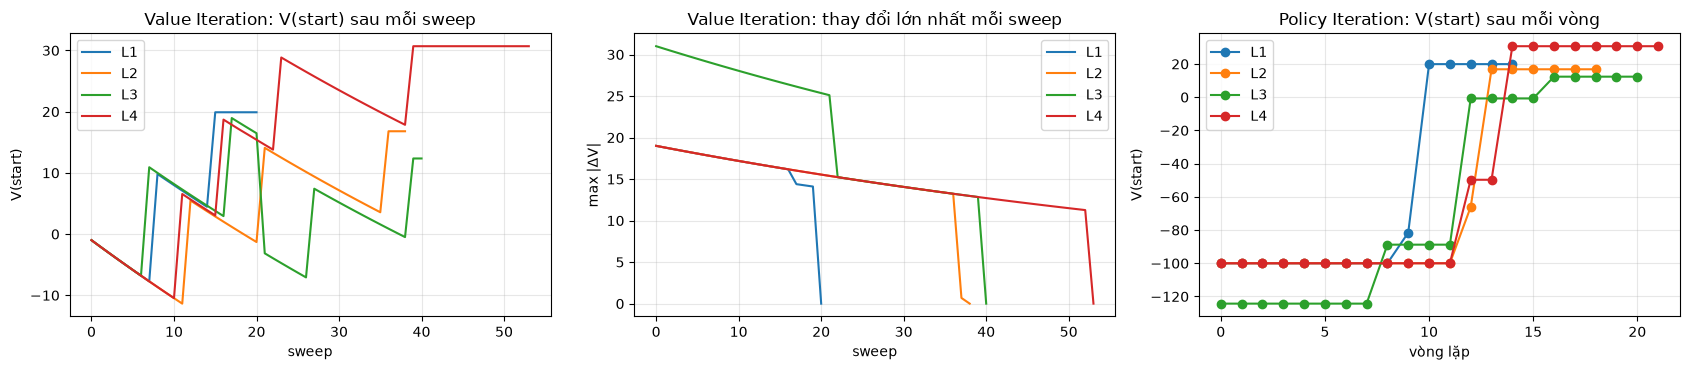

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
for name in ENVS:
    ax[0].plot(OPT[name]["hist"]["v_start"], label=name)
    ax[1].plot(OPT[name]["hist"]["deltas"], label=name)
    ax[2].plot([h["V_start"] for h in OPT[name]["pi_hist"]], "o-", label=name)
ax[0].set(title="Value Iteration: V(start) sau mỗi sweep", xlabel="sweep", ylabel="V(start)")
ax[1].set(title="Value Iteration: thay đổi lớn nhất mỗi sweep", xlabel="sweep", ylabel="max |ΔV|")
ax[2].set(title="Policy Iteration: V(start) sau mỗi vòng", xlabel="vòng lặp", ylabel="V(start)")
for a in ax:
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/dp_hoi_tu.png", dpi=120); plt.show()

**Nhận xét.**
- **Value Iteration** bắt đầu từ $V_0 = 0$. Sau $k$ sweep, $V_k(S)$ chính là return tốt nhất robot gom được **trong $k$ bước** (cộng phần đuôi $\gamma^k \cdot 0$). Vì vậy hình bên trái có dạng **răng cưa**:
  - $k$ còn nhỏ, chưa kịp giao kiện nào: chỉ có phạt bước, nên V(start) = −1, −2, −3…
  - $k$ vừa đủ để giao thêm một kiện: V(start) **nhảy lên** khoảng +20.
  - Sau mỗi lần nhảy, V(start) lại giảm dần cho tới khi tầm nhìn đủ để giao kiện tiếp theo.

  Khi $k$ ≥ độ dài lộ trình tối ưu (L1: 16, L2: 37, L3: 40, L4: 40 bước), V(start) đứng yên ở $V^*$. Môi trường tất định nên ngay sau đó max |ΔV| rơi về 0 (hình giữa).
- **Policy Iteration:** chỉ cần khoảng 15–22 vòng lớn. Nhưng các vòng đầu đánh giá những policy chưa bao giờ giao xong hàng, nên $V$ phải hội tụ từ từ về $-1/(1-\gamma) = -100$ (hơn 1 nghìn sweep mỗi vòng).
- Cả hai cho **cùng một** $V^*$ (cột “PI = VI?” ở bảng trên).

## 7. Học không cần mô hình: Monte Carlo, SARSA, Q-learning

Agent **không** biết `NS`, `R`; nó chỉ gọi `env.reset()` / `env.step(a)` và tự cập nhật bảng $Q(s,a)$.

**Chọn hành động ε-greedy:** với xác suất ε chọn ngẫu nhiên (khám phá), còn lại chọn $\arg\max_a Q(s,a)$ (khai thác). ε giảm tuyến tính từ `eps_start` xuống `eps_end` trong 80% số episode đầu.

| Thuật toán | Cập nhật | Đặc điểm |
|---|---|---|
| **Monte Carlo** (first-visit) | $Q(s_t,a_t) \leftarrow Q + \alpha\,[G_t - Q]$, với $G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots$ | chờ **hết episode** mới cập nhật; không bootstrap |
| **SARSA** (TD, on-policy) | $Q(s,a) \leftarrow Q + \alpha\,[r + \gamma Q(s',a') - Q]$ | dùng **action $a'$ thật sự sẽ đi** (theo ε-greedy) |
| **Q-learning** (TD, off-policy) | $Q(s,a) \leftarrow Q + \alpha\,[r + \gamma \max_{a'} Q(s',a') - Q]$ | dùng **action tốt nhất** ở $s'$ dù có đi hay không |

Ở bước kết thúc (giao xong hết) mục tiêu chỉ còn $r$. Khi episode bị cắt do `max_steps` thì TD vẫn bootstrap (state đó chưa thật sự kết thúc).

### Khám phá — chi tiết quyết định thuật toán có học được hay không
- **SARSA, Q-learning: khởi tạo lạc quan** $Q_0 = \sum_i r^{\text{giao}}_i$ (lớn hơn mọi giá trị thật). Action chưa thử luôn trông hứa hẹn hơn → agent tự đi thử. *Chú ý:* $Q_0 = 0$ **không** lạc quan ở bài này vì return có thể dương (+20 mỗi kiện) → agent ngừng khám phá quá sớm (mục 11.2).
- **Monte Carlo: dùng Monte Carlo ES** (*exploring starts*, Sutton & Barto §5.3). MC chỉ cập nhật khi hết episode, nên trong cả episode $Q$ đứng yên. Nếu policy tham lam chọn một hành động làm robot đứng yên (đâm tường, Pickup sai) thì robot lặp lại nó tới khi bị cắt, mọi return đều ≈ −100 và không học được gì (mục 11.1). MC-ES bắt đầu mỗi episode từ **(state, action) ngẫu nhiên** rồi đi theo policy tham lam. Episode bắt đầu gần đích sẽ kết thúc thật → giá trị đúng lan dần ngược về điểm xuất phát.
- Môi trường tất định + policy tham lam ⇒ mỗi return chính là giá trị **chính xác** của policy hiện tại, nên MC dùng α = 1 (thay $Q$ bằng return mới nhất).
- Episode MC bị cắt ở `max_steps`: phần return còn thiếu được coi như robot đi lòng vòng mãi: $-1/(1-\gamma) = -100$.

In [13]:
def eps_greedy(q_row, eps, rng):
    """q_row = list 6 giá trị Q(s, ·)."""
    if rng.random() < eps:
        return rng.randrange(len(q_row))
    return q_row.index(max(q_row))


def mc_update(Q, traj, terminated, alpha, gamma, trunc_value=-100.0):
    """Đi ngược từ cuối episode: G_t = r_{t+1} + γ·G_{t+1}; chỉ cập nhật lần gặp ĐẦU TIÊN của (s, a)."""
    first = {}
    for t, (s, a, _) in enumerate(traj):
        first.setdefault((s, a), t)
    G = 0.0 if terminated else trunc_value          # bị cắt: coi như đi lòng vòng mãi
    for t in range(len(traj) - 1, -1, -1):
        s, a, r = traj[t]
        G = r + gamma * G
        if first[(s, a)] == t:
            Q[s][a] += alpha * (G - Q[s][a])


def mc_es_episode(env, Q, alpha, gamma, eps, rng):
    """Monte Carlo ES: (state, action) đầu ngẫu nhiên, sau đó đi theo policy tham lam."""
    s, _ = env.reset(options={"random_start": True})
    a = rng.randrange(env.nA)
    traj, done, term = [], False, False
    while not done:
        s2, r, term, trunc, _ = env.step(a)
        traj.append((s, a, r))
        s, done = s2, term or trunc
        if not done:
            a = eps_greedy(Q[s], eps, rng)
    mc_update(Q, traj, term, alpha, gamma)
    return sum(r for _, _, r in traj)


def mc_onpolicy_episode(env, Q, alpha, gamma, eps, rng):
    """Monte Carlo on-policy thường: luôn xuất phát ở S, chọn action ε-greedy (dùng ở mục 11.1)."""
    s, _ = env.reset()
    traj, done, term = [], False, False
    while not done:
        a = eps_greedy(Q[s], eps, rng)
        s2, r, term, trunc, _ = env.step(a)
        traj.append((s, a, r))
        s, done = s2, term or trunc
    mc_update(Q, traj, term, alpha, gamma)
    return sum(r for _, _, r in traj)


def sarsa_episode(env, Q, alpha, gamma, eps, rng):
    s, _ = env.reset()
    a = eps_greedy(Q[s], eps, rng)
    G, done = 0.0, False
    while not done:
        s2, r, term, trunc, _ = env.step(a)
        a2 = eps_greedy(Q[s2], eps, rng)                     # action tiếp theo THẬT SỰ sẽ làm
        target = r if term else r + gamma * Q[s2][a2]
        Q[s][a] += alpha * (target - Q[s][a])
        s, a, G, done = s2, a2, G + r, term or trunc
    return G


def q_learning_episode(env, Q, alpha, gamma, eps, rng):
    s, _ = env.reset()
    G, done = 0.0, False
    while not done:
        a = eps_greedy(Q[s], eps, rng)
        s2, r, term, trunc, _ = env.step(a)
        target = r if term else r + gamma * max(Q[s2])       # action TỐT NHẤT ở s'
        Q[s][a] += alpha * (target - Q[s][a])
        s, G, done = s2, G + r, term or trunc
    return G


ALGOS = {"mc": ("Monte Carlo ES", mc_es_episode),
         "sarsa": ("SARSA", sarsa_episode),
         "ql": ("Q-learning", q_learning_episode),
         "mc_on": ("MC on-policy", mc_onpolicy_episode)}

Hàm `train` dùng chung cho mọi thuật toán: chạy từng episode, cứ một khoảng lại **đánh giá policy tham lam (ε = 0) từ điểm xuất phát S** để vẽ đường học. Ta đếm cả **số bước tương tác** với môi trường, vì episode MC-ES ngắn hơn nhiều so với episode từ S. So sánh theo số bước công bằng hơn so sánh theo số episode.

In [14]:
def greedy_eval(env, Q):
    """Chạy policy tham lam (ε = 0) từ S -> (return, số bước, giao xong?)."""
    s, _ = env.reset()
    G = 0.0
    for k in range(env.max_steps):
        q = Q[s]
        s, r, term, trunc, _ = env.step(q.index(max(q)))
        G += r
        if term:
            return G, k + 1, True
    return G, env.max_steps, False


def train(env, algo, episodes, alpha, eps_start, eps_end, q_init=0.0, gamma=GAMMA, seed=0, n_eval=80):
    """Huấn luyện một thuật toán -> (bảng Q numpy, lịch sử học)."""
    rng = random.Random(seed)
    env.reset(seed=seed)                                 # seed cho phần ngẫu nhiên của env (exploring starts)
    if q_init == "lac_quan":
        q_init = float(sum(env.r_deliver))               # ≥ mọi return có thể đạt được
    Q = [[float(q_init)] * env.nA for _ in range(env.nS)]   # list Python: nhanh hơn numpy khi truy cập lẻ
    run_episode = ALGOS[algo][1]
    every = max(1, episodes // n_eval)
    hist = dict(eval_ep=[], eval_steps=[], eval_return=[], eval_ok=[])
    decay = (eps_start - eps_end) / (0.8 * episodes)
    n_steps, t0 = 0, time.time()
    for ep in range(episodes):
        eps = max(eps_end, eps_start - decay * ep)
        run_episode(env, Q, alpha, gamma, eps, rng)
        n_steps += env.steps
        if (ep + 1) % every == 0 or ep == episodes - 1:
            G, n, ok = greedy_eval(env, Q)
            hist["eval_ep"].append(ep + 1)
            hist["eval_steps"].append(n_steps)
            hist["eval_return"].append(G)
            hist["eval_ok"].append(ok)
    hist["time"] = time.time() - t0
    hist["total_steps"] = n_steps
    return np.array(Q), hist


def converged_at(hist, G_opt):
    """Episode / số bước mà từ đó trở đi mọi lần đánh giá đều đạt return tối ưu (None = chưa hội tụ)."""
    ok = np.isclose(hist["eval_return"], G_opt)
    for i in range(len(ok)):
        if ok[i:].all():
            return hist["eval_ep"][i], hist["eval_steps"][i]
    return None, None


def evaluate(env, Q, opt):
    """So policy tham lam của Q với đáp án DP."""
    pi = Q.argmax(axis=1)
    steps, ok = rollout(env, pi)
    G = sum(e["r"] for e in steps)
    S = env.reachable_states()
    S = S[~env.is_terminal[S]]
    acc = float((opt["Q"][S, pi[S]] >= opt["Q"][S].max(axis=1) - 1e-6).mean())
    return dict(G=G, n=len(steps), ok=ok, optimal=bool(ok and abs(G - opt["G"]) < 1e-9), acc=acc, steps=steps)

### 7.1 Siêu tham số

| | α | ε (đầu → cuối) | $Q_0$ | xuất phát mỗi episode |
|---|---|---|---|---|
| Q-learning | 0.3 | 0.3 → 0.01 | lạc quan $=\sum r^{\text{giao}}$ | S |
| SARSA | 0.3 | 0.3 → 0.01 | lạc quan $=\sum r^{\text{giao}}$ | S |
| Monte Carlo ES | 1.0 | 0 (tham lam) | 0 | (state, action) ngẫu nhiên |

Số episode tăng theo độ khó của map. MC cần nhiều episode hơn, nhưng mỗi episode ngắn hơn.

In [15]:
HYPER = {
    "ql":    dict(alpha=0.3, eps_start=0.3, eps_end=0.01, q_init="lac_quan"),
    "sarsa": dict(alpha=0.3, eps_start=0.3, eps_end=0.01, q_init="lac_quan"),
    "mc":    dict(alpha=1.0, eps_start=0.0, eps_end=0.0, q_init=0.0),
}
EPISODES = {
    "L1": dict(ql=5_000,  sarsa=5_000,  mc=30_000),
    "L2": dict(ql=20_000, sarsa=20_000, mc=100_000),
    "L3": dict(ql=40_000, sarsa=40_000, mc=300_000),
    "L4": dict(ql=50_000, sarsa=50_000, mc=300_000),
}
if QUICK:
    EPISODES = {m: {a: n // 4 for a, n in d.items()} for m, d in EPISODES.items()}
ALGO_ORDER = ["ql", "sarsa", "mc"]
ALGO_COLOR = {"ql": "#4e79a7", "sarsa": "#59a14f", "mc": "#e15759"}
print(json.dumps(EPISODES, indent=1))

{
 "L1": {
  "ql": 5000,
  "sarsa": 5000,
  "mc": 30000
 },
 "L2": {
  "ql": 20000,
  "sarsa": 20000,
  "mc": 100000
 },
 "L3": {
  "ql": 40000,
  "sarsa": 40000,
  "mc": 300000
 },
 "L4": {
  "ql": 50000,
  "sarsa": 50000,
  "mc": 300000
 }
}


## 8. Huấn luyện: 3 thuật toán × 4 map × nhiều seed

Mỗi cặp (map, thuật toán) chạy với các seed trong `SEEDS`. Kết quả được so với đáp án tối ưu của Value Iteration:
- **return**: return (không chiết khấu) của policy tham lam khi đi từ S;
- **tối ưu**: số seed đạt đúng return tối ưu;
- **đúng (%)**: tỉ lệ state (trong mọi state đạt tới được) mà action tham lam là action tối ưu theo $Q^*$.

⏱ Ô này tốn thời gian nhất (khoảng 7 phút trên Colab, phần lớn là Monte Carlo ES ở L3, L4).

In [16]:
RESULTS = {}
t_all = time.time()
for name, env in ENVS.items():
    for algo in ALGO_ORDER:
        runs = []
        for seed in SEEDS:
            Q, hist = train(env, algo, EPISODES[name][algo], seed=seed, **HYPER[algo])
            ev = evaluate(env, Q, OPT[name])
            ev["conv_ep"], ev["conv_steps"] = converged_at(hist, OPT[name]["G"])
            runs.append(dict(seed=seed, Q=Q, hist=hist, **ev))
        RESULTS[(name, algo)] = runs
        Gs = [r["G"] for r in runs]
        print(f"{name} {ALGOS[algo][0]:15} {EPISODES[name][algo]:>8,} ep | return {np.mean(Gs):6.1f} ± {np.std(Gs):4.1f} "
              f"(tối ưu {OPT[name]['G']:.0f}) | tối ưu {sum(r['optimal'] for r in runs)}/{len(runs)} seed | "
              f"đúng {100 * np.mean([r['acc'] for r in runs]):5.1f}% | {np.mean([r['hist']['time'] for r in runs]):5.1f} s/seed",
              flush=True)
print(f"\nTổng thời gian huấn luyện: {time.time() - t_all:.0f} s")

L1 Q-learning         5,000 ep | return   24.0 ±  0.0 (tối ưu 24) | tối ưu 3/3 seed | đúng  57.3% |   0.1 s/seed


L1 SARSA              5,000 ep | return   23.3 ±  0.5 (tối ưu 24) | tối ưu 1/3 seed | đúng  77.9% |   0.1 s/seed


L1 Monte Carlo ES    30,000 ep | return   24.0 ±  0.0 (tối ưu 24) | tối ưu 3/3 seed | đúng 100.0% |   0.7 s/seed


L2 Q-learning        20,000 ep | return   23.0 ±  0.0 (tối ưu 23) | tối ưu 3/3 seed | đúng  61.2% |   0.9 s/seed


L2 SARSA             20,000 ep | return   23.0 ±  0.0 (tối ưu 23) | tối ưu 3/3 seed | đúng  79.6% |   0.9 s/seed


L2 Monte Carlo ES   100,000 ep | return   23.0 ±  0.0 (tối ưu 23) | tối ưu 3/3 seed | đúng 100.0% |   4.4 s/seed


... (3 outputs left out)

L4 Q-learning        50,000 ep | return   40.0 ±  0.0 (tối ưu 40) | tối ưu 3/3 seed | đúng  27.4% |   5.2 s/seed


L4 SARSA             50,000 ep | return   40.0 ±  0.0 (tối ưu 40) | tối ưu 3/3 seed | đúng  51.0% |   5.2 s/seed


L4 Monte Carlo ES   300,000 ep | return -120.7 ± 112.5 (tối ưu 40) | tối ưu 0/3 seed | đúng  71.4% |  56.8 s/seed



Tổng thời gian huấn luyện: 302 s


### 8.1 Đường học

Trục ngang là **số bước tương tác** với môi trường (thang log). Trục dọc là return của policy tham lam khi đi từ S: đường đậm là trung vị (median) các seed, vùng mờ là min–max. Nét đứt là return tối ưu của DP. Giá trị quá thấp (policy còn đi lòng vòng) bị cắt khỏi khung hình.

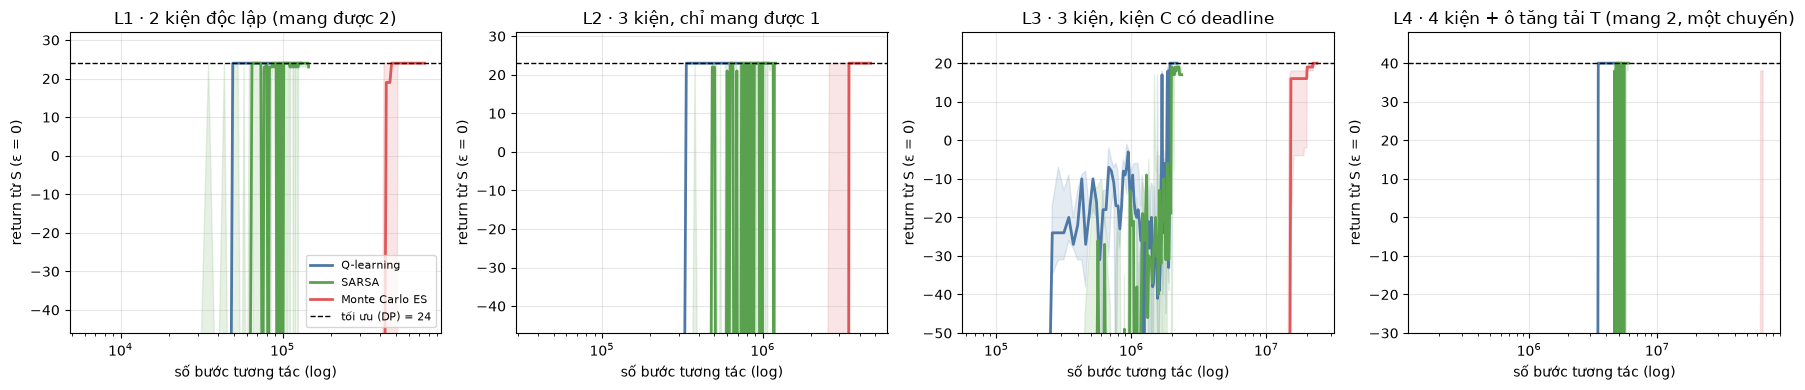

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, ENVS):
    G_opt = OPT[name]["G"]
    for algo in ALGO_ORDER:
        runs = RESULTS[(name, algo)]
        x = np.mean([r["hist"]["eval_steps"] for r in runs], axis=0)
        y = np.array([r["hist"]["eval_return"] for r in runs])
        ax.plot(x, np.median(y, axis=0), color=ALGO_COLOR[algo], lw=2, label=ALGOS[algo][0])
        ax.fill_between(x, y.min(0), y.max(0), color=ALGO_COLOR[algo], alpha=.15)
    ax.axhline(G_opt, color="k", ls="--", lw=1, label=f"tối ưu (DP) = {G_opt:.0f}")
    ax.set_xscale("log")
    ax.set_ylim(G_opt - 70, G_opt + 8)
    ax.set(title=ENVS[name].title, xlabel="số bước tương tác (log)", ylabel="return từ S (ε = 0)")
    ax.grid(alpha=.3)
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/duong_hoc.png", dpi=120); plt.show()

### 8.2 Bảng tổng hợp

In [18]:
SUMMARY = []
print(f"{'map':4} {'thuật toán':15} {'episode':>8} {'bước tương tác':>14} {'return':>13} {'tối ưu':>6} "
      f"{'đúng %':>7} {'hội tụ ở bước':>14} {'thời gian':>9}")
for name in ENVS:
    for algo in ALGO_ORDER:
        runs = RESULTS[(name, algo)]
        conv = [r["conv_steps"] for r in runs if r["conv_steps"] is not None]
        row = dict(map=name, algo=ALGOS[algo][0], episodes=EPISODES[name][algo],
                   steps=int(np.mean([r["hist"]["total_steps"] for r in runs])),
                   G_mean=float(np.mean([r["G"] for r in runs])), G_std=float(np.std([r["G"] for r in runs])),
                   G_opt=OPT[name]["G"], n_opt=sum(r["optimal"] for r in runs), n_seed=len(runs),
                   acc=float(np.mean([r["acc"] for r in runs])),
                   conv_steps=int(np.mean(conv)) if len(conv) == len(runs) else None,
                   time=float(np.mean([r["hist"]["time"] for r in runs])))
        SUMMARY.append(row)
        conv_txt = f"{row['conv_steps']:,}" if row["conv_steps"] else f"chưa ({len(conv)}/{len(runs)})"
        print(f"{name:4} {row['algo']:15} {row['episodes']:>8,} {row['steps']:>14,} "
              f"{row['G_mean']:>6.1f} ± {row['G_std']:<4.1f} {row['n_opt']:>3}/{row['n_seed']} "
              f"{100 * row['acc']:>6.1f}% {conv_txt:>14} {row['time']:>7.1f} s")
    print()

map  thuật toán       episode bước tương tác        return tối ưu  đúng %  hội tụ ở bước thời gian
L1   Q-learning         5,000        129,973   24.0 ± 0.0    3/3   57.3%         49,285     0.1 s
L1   SARSA              5,000        144,827   23.3 ± 0.5    1/3   77.9%     chưa (1/3)     0.1 s
L1   Monte Carlo ES    30,000        751,277   24.0 ± 0.0    3/3  100.0%        480,347     0.7 s

L2   Q-learning        20,000      1,072,749   23.0 ± 0.0    3/3   61.2%        334,696     0.9 s
L2   SARSA             20,000      1,199,533   23.0 ± 0.0    3/3   79.6%      1,133,505     0.9 s
L2   Monte Carlo ES   100,000      4,689,520   23.0 ± 0.0    3/3  100.0%      3,245,971     4.4 s

L3   Q-learning        40,000      2,173,791   20.0 ± 0.0    3/3   77.8%      1,937,794     1.9 s
L3   SARSA             40,000      2,359,262   17.7 ± 0.9    0/3   66.5%     chưa (0/3)     1.9 s
L3   Monte Carlo ES   300,000     23,638,595   20.0 ± 0.0    3/3   98.8%     21,830,721    22.4 s

L4   Q-learning 

### 8.3 Lộ trình mà mỗi thuật toán học được (seed đầu tiên)

In [19]:
for name, env in ENVS.items():
    print(f"── {env.title}")
    print(f"   {'DP tối ưu':15} {OPT[name]['n']:>3} bước, return {OPT[name]['G']:+4.0f} | giao: {order_text(OPT[name]['steps'])}")
    for algo in ALGO_ORDER:
        r = RESULTS[(name, algo)][0]
        tag = "✅" if r["optimal"] else ("⚠ chưa tối ưu" if r["ok"] else "❌ không giao xong")
        print(f"   {ALGOS[algo][0]:15} {r['n']:>3} bước, return {r['G']:+4.0f} | giao: {order_text(r['steps']) or '—'} {tag}")
    print()

── L1 · 2 kiện độc lập (mang được 2)
   DP tối ưu        16 bước, return  +24 | giao: B → A
   Q-learning       16 bước, return  +24 | giao: B → A ✅
   SARSA            17 bước, return  +23 | giao: A → B ⚠ chưa tối ưu
   Monte Carlo ES   16 bước, return  +24 | giao: B → A ✅

── L2 · 3 kiện, chỉ mang được 1
   DP tối ưu        37 bước, return  +23 | giao: B → C → A
   Q-learning       37 bước, return  +23 | giao: B → C → A ✅
   SARSA            37 bước, return  +23 | giao: B → C → A ✅
   Monte Carlo ES   37 bước, return  +23 | giao: B → C → A ✅

── L3 · 3 kiện, kiện C có deadline
   DP tối ưu        40 bước, return  +20 | giao: C → B → A
   Q-learning       40 bước, return  +20 | giao: C → B → A ✅
   SARSA            41 bước, return  +19 | giao: C → B → A ⚠ chưa tối ưu
   Monte Carlo ES   40 bước, return  +20 | giao: C → B → A ✅

── L4 · 4 kiện + ô tăng tải T (mang 2, một chuyến)
   DP tối ưu        40 bước, return  +40 | giao: A → B → C → D
   Q-learning       40 bước, return  +40 | gi

**Nhận xét: so sánh 3 thuật toán** (số liệu của lần chạy đầy đủ, `QUICK = False`, 3 seed)

| | Q-learning | SARSA | Monte Carlo ES |
|---|---|---|---|
| Tối ưu từ S | 4/4 map, mọi seed | L2, L4; chưa tối ưu ở L1 (1/3 seed), L3 (0/3) | L1–L3; **chưa** ở L4 (0/3) |
| Bước tương tác tới khi hội tụ | ít nhất (L1 ≈ 49 nghìn, L4 ≈ 3,5 triệu) | nhiều hơn Q-learning | gấp ~10 lần Q-learning (L3 ≈ 22 triệu) |
| Đúng % state | 27–78% | 51–80% | 71–100% |

- **Q-learning** nhanh nhất. Mục tiêu $r + \gamma \max_{a'} Q(s',a')$ luôn hướng về policy tối ưu, kể cả khi robot đang đi ε-greedy.
- **SARSA** dùng action **thật sự sẽ đi**, kể cả action khám phá ngẫu nhiên. Vì vậy $Q$ của nó là giá trị của policy ε-greedy, không phải của policy tối ưu. Khi hai lộ trình chỉ chênh 1–2 bước (L1: 16 so với 17; L3: 40 so với 41), sai lệch nhỏ này đủ làm SARSA chọn lộ trình dài hơn một chút. Muốn SARSA đạt tối ưu cần giảm ε chậm hơn và chạy nhiều episode hơn.
- **Monte Carlo ES** chỉ cập nhật khi hết episode và dùng return thật, nên cần rất nhiều episode. Bù lại, nó xuất phát ngẫu nhiên nên học đúng ở gần như mọi state. Ở L4 (6041 state đạt tới), 300 nghìn episode vẫn chưa đủ: return dao động mạnh giữa các seed. Đây là ví dụ **hội tụ chậm**, phân tích thêm ở mục 11.
- Cột *đúng %* thấp ở Q-learning/SARSA **không** có nghĩa là policy tệ. Hai thuật toán này luôn xuất phát ở S nên chỉ cần đúng dọc đường đi từ S (xem mục 11.3).

## 9. Trực quan hóa policy cuối cùng

Mỗi hình nhỏ là một **giai đoạn** của lộ trình, tức một tổ hợp trạng thái các kiện (và ô tăng tải). Trong mỗi hình:
- nền xanh = $V^*$ (DP), càng đậm càng tốt;
- ký hiệu = action của policy đã học tại **mọi ô** (↑↓←→, P = Pickup, D = Drop);
- **màu đỏ** = action khác action tối ưu;
- đường cam = đoạn robot thực sự đi trong giai đoạn đó.

Với map có deadline, đồng hồ $t$ được giữ cố định bằng giá trị lúc bắt đầu giai đoạn.

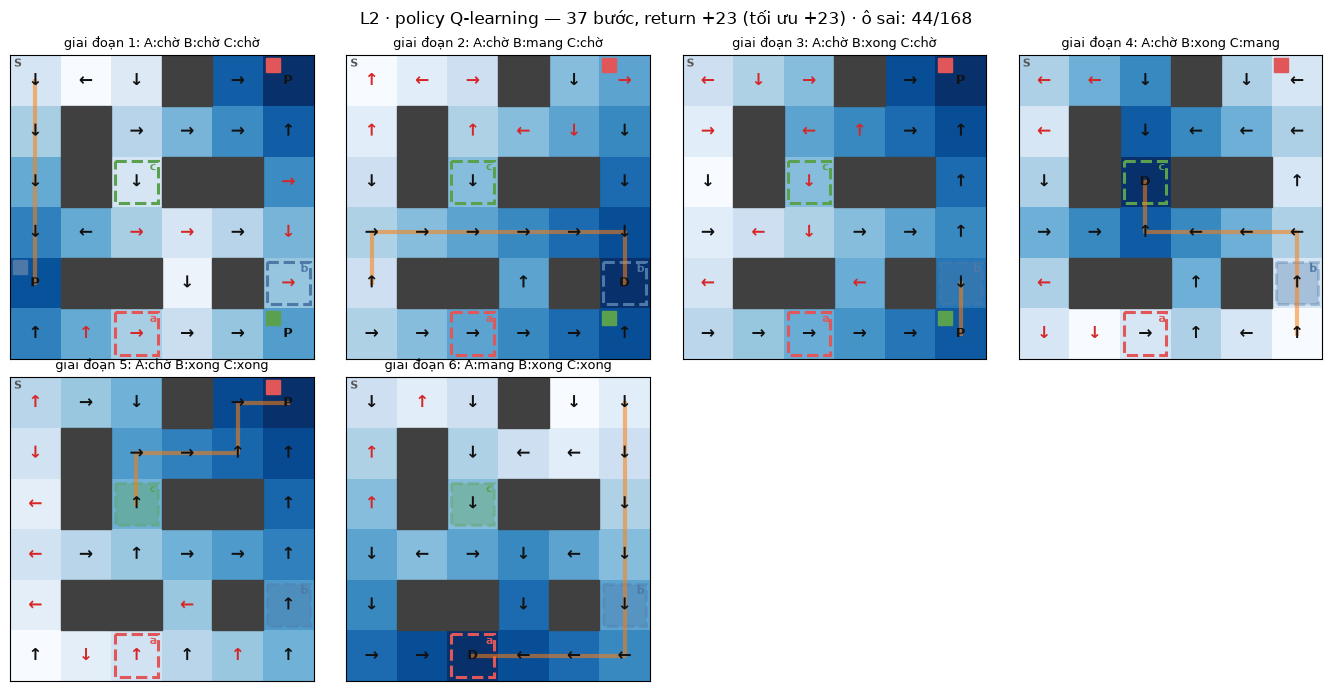

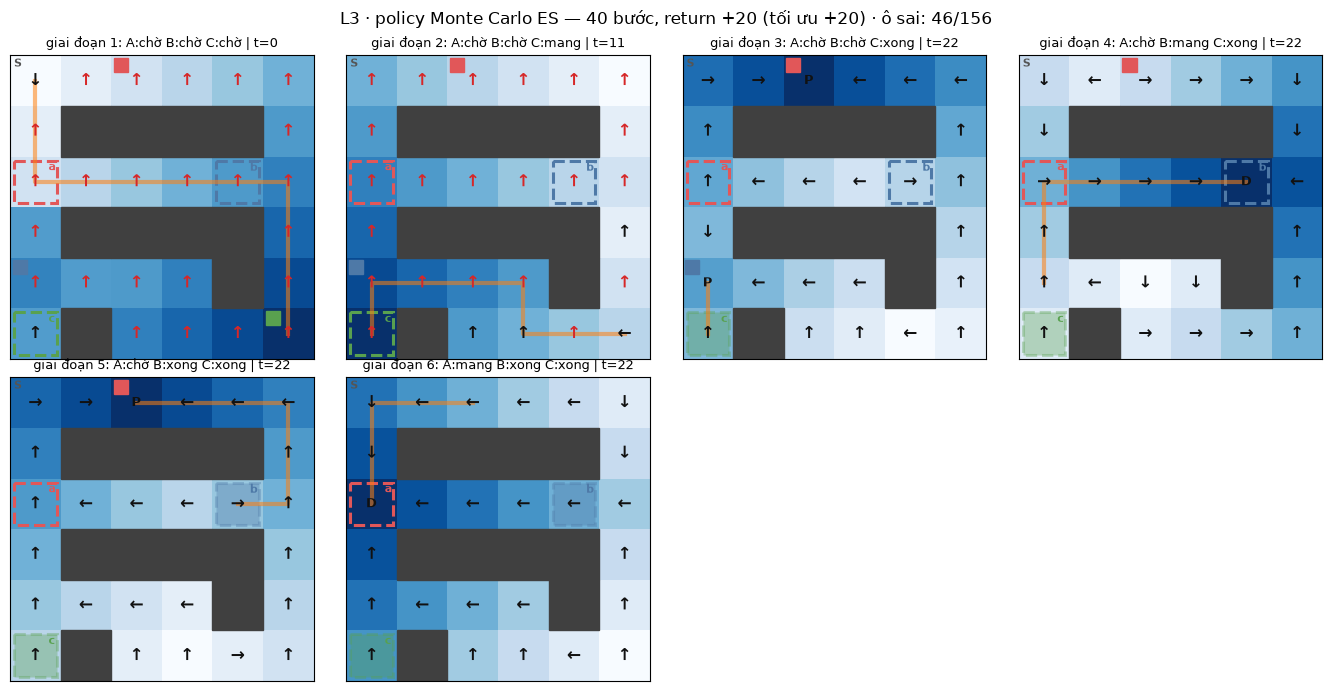

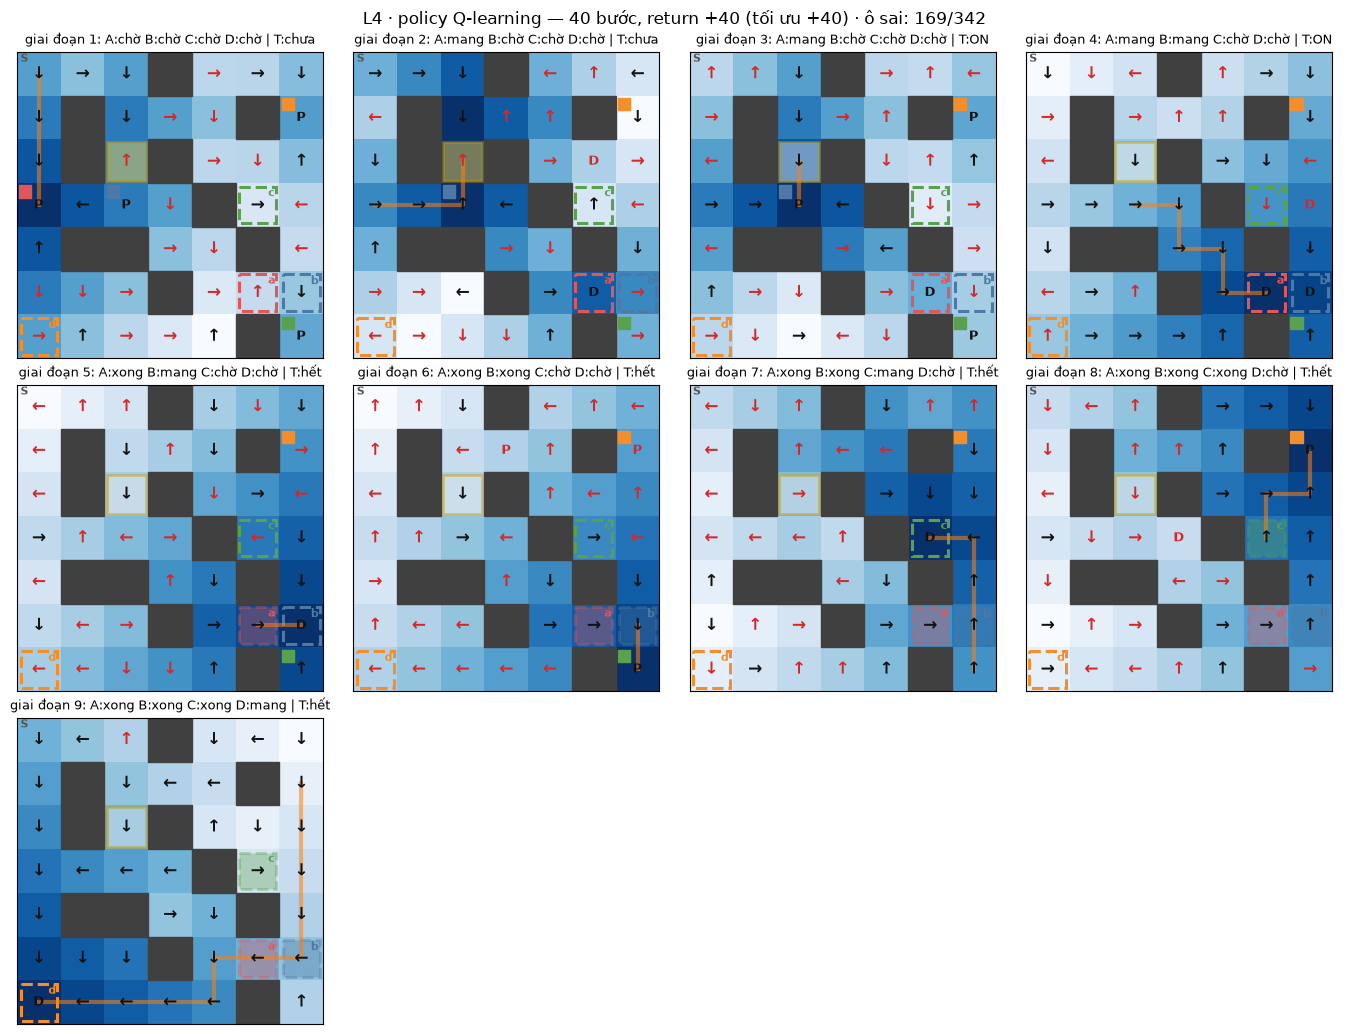

In [20]:
def plot_policy(env, pi, opt, title, ncols=4, fname=None):
    steps, ok = rollout(env, pi)
    phases, prev = [], None
    for e in steps:
        r, c, pkgs, t, b = env.decode(e["s"])
        if (pkgs, b) != prev:
            phases.append(dict(s=e["s"], path=[]))
            prev = (pkgs, b)
        phases[-1]["path"].append((r, c))
    for ph, nxt in zip(phases, phases[1:] + [None]):           # nối đường sang ô đầu giai đoạn sau
        if nxt:
            ph["path"].append(nxt["path"][0])
    nrows = math.ceil(len(phases) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.5 * nrows))
    axes = np.atleast_1d(axes).ravel()
    n_wrong = n_cells = 0
    for k, (ax, ph) in enumerate(zip(axes, phases)):
        _, _, pkgs, t, b = env.decode(ph["s"])
        arrows = [[""] * env.W for _ in range(env.H)]
        values = np.full((env.H, env.W), np.nan)
        wrong = np.zeros((env.H, env.W), dtype=bool)
        for r in range(env.H):
            for c in range(env.W):
                if (r, c) in env.walls:
                    continue
                s = env.encode(r, c, pkgs, t, b)
                arrows[r][c] = ARROWS[pi[s]]
                values[r, c] = opt["V"][s]
                wrong[r, c] = opt["Q"][s, pi[s]] < opt["Q"][s].max() - 1e-6
        n_wrong += wrong.sum()
        n_cells += env.H * env.W - len(env.walls)
        sub = " ".join(f"{n}:{SHORT[x]}" for n, x in zip(env.names, pkgs))
        if env.dl is not None:
            sub += f" | t={t}"
        if env.booster:
            sub += f" | T:{['chưa', 'ON', 'hết'][b]}"
        draw_state(env, ph["s"], ax, title=f"giai đoạn {k + 1}: {sub}", values=values, arrows=arrows,
                   wrong=wrong, path=ph["path"])
    for ax in axes[len(phases):]:
        ax.axis("off")
    fig.suptitle(f"{title} — {len(steps)} bước, return {sum(e['r'] for e in steps):+.0f} "
                 f"(tối ưu {opt['G']:+.0f}) · ô sai: {n_wrong}/{n_cells}", fontsize=12)
    plt.tight_layout()
    if fname:
        plt.savefig(f"{OUT}/{fname}", dpi=120)
    plt.show()


for name, algo in [("L2", "ql"), ("L3", "mc"), ("L4", "ql")]:
    pi = RESULTS[(name, algo)][0]["Q"].argmax(axis=1)
    plot_policy(ENVS[name], pi, OPT[name], f"{name} · policy {ALGOS[algo][0]}", fname=f"policy_{name}_{algo}.png")

**Đọc hình:** trên đường robot thực sự đi (đường cam), action của Q-learning trùng tối ưu. Ở những ô xa đường đi thì Q-learning ít khi ghé, nên nhiều action **sai (đỏ)**. Đây là đặc điểm của học từ một điểm xuất phát cố định (xem thêm mục 11.3). Monte Carlo ES xuất phát ngẫu nhiên nên đúng gần như ở mọi ô.

## 10. Thay đổi reward / tham số môi trường → policy thay đổi

Mỗi thí nghiệm đổi **một** yếu tố, giải lại bằng Value Iteration (đáp án chính xác) và **huấn luyện lại Q-learning** để kiểm tra agent có tự học ra hành vi mới không. Q-learning ở đây chạy **gấp đôi** số episode so với mục 8, vì có biến thể khó hơn bản gốc. Ví dụ với D = 25, lộ trình A → C → B phải canh thời gian rất sát: với 40k episode, cả 3 seed đều chưa tìm ra; với 80k episode thì cả 3 đều tìm ra.

In [21]:
def move_booster(grid, pos):
    """Đặt ô tăng tải T sang vị trí pos (None = bỏ ô T)."""
    g = [list(row.replace(" ", "").replace("T", ".")) for row in grid]
    if pos is not None:
        assert g[pos[0]][pos[1]] == ".", "vị trí mới phải là ô trống"
        g[pos[0]][pos[1]] = "T"
    return ["".join(row) for row in g]


def variant_study(base, variants, fname):
    """variants: list (nhãn, cfg). Giải DP + huấn luyện Q-learning cho từng biến thể, vẽ lộ trình."""
    fig, axes = plt.subplots(1, len(variants), figsize=(4.3 * len(variants), 4.6))
    rows = []
    for ax, (label, cfg) in zip(np.atleast_1d(axes), variants):
        env = MultiDeliveryEnv(cfg)
        pi, V, Q, _ = value_iteration(env)
        steps, ok = rollout(env, pi)
        G = sum(e["r"] for e in steps)
        Qq, _ = train(env, "ql", 2 * EPISODES[base]["ql"], seed=0, **HYPER["ql"])
        st_q, ok_q = rollout(env, Qq.argmax(axis=1))
        G_q = sum(e["r"] for e in st_q)
        rows.append((label, len(steps), G, order_text(steps), route_text(steps), len(st_q), G_q, order_text(st_q)))
        path = [env.decode(env.s0)[:2]] + [env.decode(e["s2"])[:2] for e in steps]
        draw_state(env, env.s0, ax, path=path,
                   title=f"{label}\nDP: {len(steps)} bước, return {G:+.0f}, giao {order_text(steps)}")
        for k, e in enumerate(steps):                       # đánh số bước tại các sự kiện
            if e["event"]:
                r, c = env.decode(e["s2"])[:2]
                ax.annotate(str(k + 1), (c, r), xytext=(c + .22, r - .25), fontsize=7, zorder=7,
                            bbox=dict(boxstyle="round,pad=.12", fc="white", ec="#888", lw=.6))
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=120); plt.show()
    print(f"{'biến thể':34} {'DP: bước':>8} {'return':>7}  {'thứ tự giao':12} | {'Q-learning: bước':>16} {'return':>7}  thứ tự")
    for label, n, G, order, route, nq, Gq, oq in rows:
        print(f"{label:34} {n:>8} {G:>+7.0f}  {order:12} | {nq:>16} {Gq:>+7.0f}  {oq} {'✅' if abs(Gq - G) < 1e-9 else '❌'}")
    for r in rows:
        print(f"\n{r[0]}: {r[4]}")
    return rows

### 10.1 Deadline (L3): phạt trễ và độ dài deadline

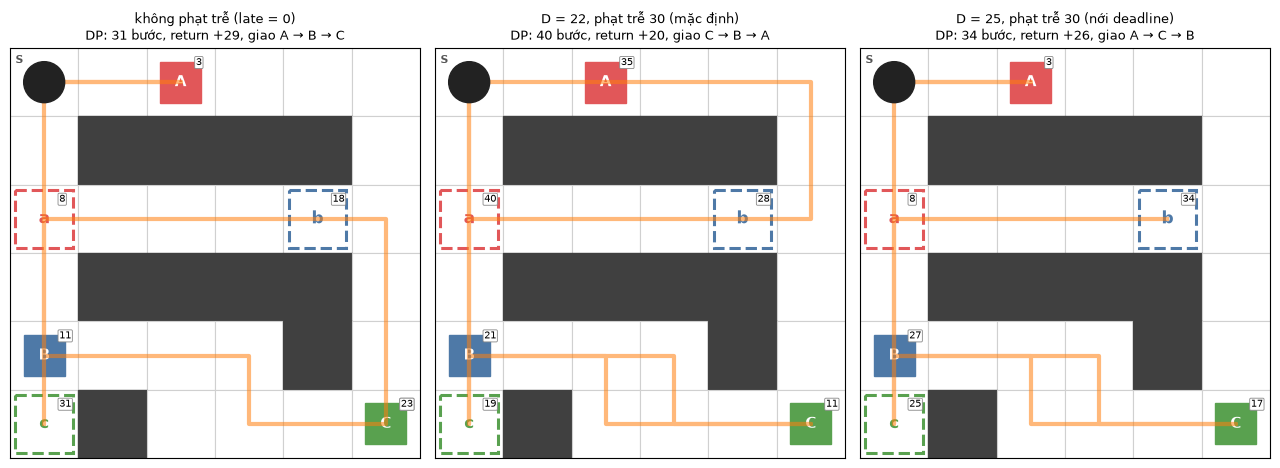

biến thể                           DP: bước  return  thứ tự giao  | Q-learning: bước  return  thứ tự
không phạt trễ (late = 0)                31     +29  A → B → C    |               31     +29  A → B → C ✅
D = 22, phạt trễ 30 (mặc định)           40     +20  C → B → A    |               40     +20  C → B → A ✅
D = 25, phạt trễ 30 (nới deadline)       34     +26  A → C → B    |               34     +26  A → C → B ✅

không phạt trễ (late = 0): lấy kiện A (bước 3) → giao kiện A (bước 8) → lấy kiện B (bước 11) → giao kiện B (bước 18) → trễ deadline! (bước 22) → lấy kiện C (bước 23) → giao kiện C (bước 31)

D = 22, phạt trễ 30 (mặc định): lấy kiện C (bước 11) → giao kiện C (bước 19) → lấy kiện B (bước 21) → giao kiện B (bước 28) → lấy kiện A (bước 35) → giao kiện A (bước 40)

D = 25, phạt trễ 30 (nới deadline): lấy kiện A (bước 3) → giao kiện A (bước 8) → lấy kiện C (bước 17) → giao kiện C (bước 25) → lấy kiện B (bước 27) → giao kiện B (bước 34)


In [22]:
cfg = MAPS["L3"]
rows_dl = variant_study("L3", [
    ("không phạt trễ (late = 0)", dict(cfg, rewards=dict(cfg["rewards"], late=0))),
    ("D = 22, phạt trễ 30 (mặc định)", cfg),
    ("D = 25, phạt trễ 30 (nới deadline)", dict(cfg, deadline={"C": 25})),
], "thi_nghiem_deadline.png")

- **Không phạt trễ:** robot đi theo thứ tự gần nhất A → B → C (31 bước). Kiện C bị trễ nhưng không mất gì.
- **Phạt 30, D = 22:** chỉ còn cách đi **lấy C ngay từ đầu** (C giao ở bước 19, còn dư 3 bước). Tổng đường dài hơn (40 bước) nhưng tránh được −30.
- **D = 25:** robot giao A trước (A ngay trên đường) rồi mới C, vẫn kịp ở bước 25, cuối cùng mới đến B.

→ Nhờ có $t$ trong state, agent biết “còn bao nhiêu thời gian”. Policy đổi thứ tự giao theo đúng mức phạt và độ dài deadline.

### 10.2 Đơn ưu tiên (L2): tăng reward của kiện A

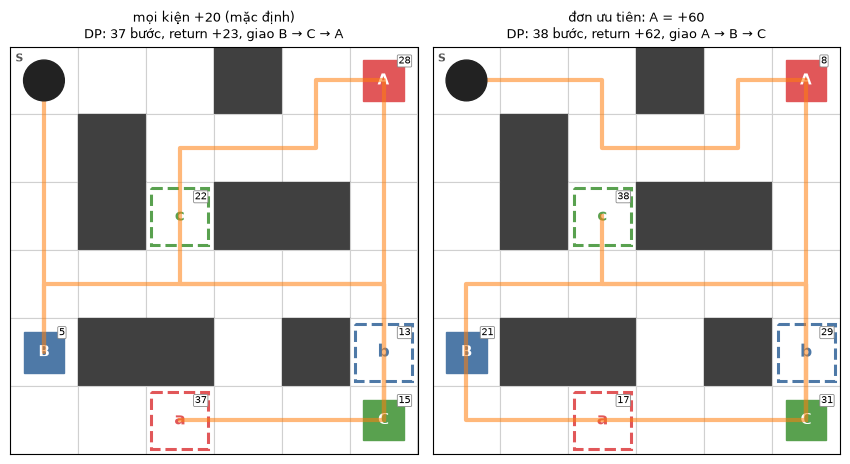

biến thể                           DP: bước  return  thứ tự giao  | Q-learning: bước  return  thứ tự
mọi kiện +20 (mặc định)                  37     +23  B → C → A    |               37     +23  B → C → A ✅
đơn ưu tiên: A = +60                     38     +62  A → B → C    |               38     +62  A → B → C ✅

mọi kiện +20 (mặc định): lấy kiện B (bước 5) → giao kiện B (bước 13) → lấy kiện C (bước 15) → giao kiện C (bước 22) → lấy kiện A (bước 28) → giao kiện A (bước 37)

đơn ưu tiên: A = +60: lấy kiện A (bước 8) → giao kiện A (bước 17) → lấy kiện B (bước 21) → giao kiện B (bước 29) → lấy kiện C (bước 31) → giao kiện C (bước 38)


In [23]:
cfg = MAPS["L2"]
rows_pr = variant_study("L2", [
    ("mọi kiện +20 (mặc định)", cfg),
    ("đơn ưu tiên: A = +60", dict(cfg, rewards=dict(cfg["rewards"], priority={"A": 60}))),
], "thi_nghiem_uu_tien.png")

Với $\gamma = 0.99$, reward nhận càng muộn càng bị chiết khấu ($\gamma^t$). Khi A đáng +60, giao A sớm có lợi hơn vài bước đi thêm, nên robot **chuyển A lên đầu**. Đây là cách mô hình hóa đơn ưu tiên.

### 10.3 Ô tăng tải (L4): có / không / đặt ở vị trí khác

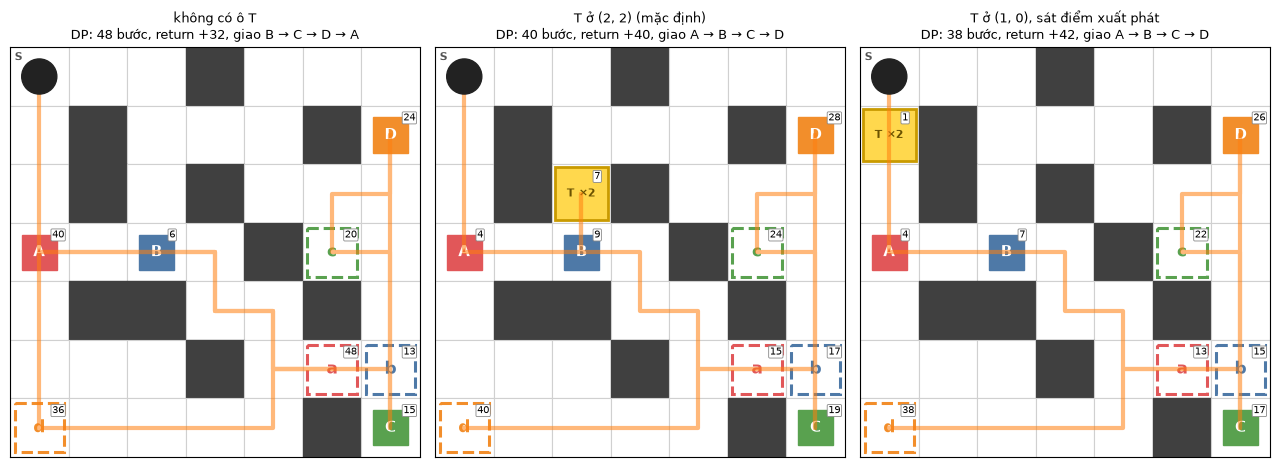

biến thể                           DP: bước  return  thứ tự giao  | Q-learning: bước  return  thứ tự
không có ô T                             48     +32  B → C → D → A |               48     +32  B → C → D → A ✅
T ở (2, 2) (mặc định)                    40     +40  A → B → C → D |               40     +40  A → B → C → D ✅
T ở (1, 0), sát điểm xuất phát           38     +42  A → B → C → D |               38     +42  A → B → C → D ✅

không có ô T: lấy kiện B (bước 6) → giao kiện B (bước 13) → lấy kiện C (bước 15) → giao kiện C (bước 20) → lấy kiện D (bước 24) → giao kiện D (bước 36) → lấy kiện A (bước 40) → giao kiện A (bước 48)

T ở (2, 2) (mặc định): lấy kiện A (bước 4) → kích hoạt ô tăng tải (bước 7) → lấy kiện B (bước 9) → giao kiện A (bước 15) → giao kiện B (bước 17) → lấy kiện C (bước 19) → giao kiện C (bước 24) → lấy kiện D (bước 28) → giao kiện D (bước 40)

T ở (1, 0), sát điểm xuất phát: kích hoạt ô tăng tải (bước 1) → lấy kiện A (bước 4) → lấy kiện B (bước 7) → giao kiện A (bước

In [24]:
cfg = MAPS["L4"]
rows_bt = variant_study("L4", [
    ("không có ô T", dict(cfg, grid=move_booster(cfg["grid"], None))),
    ("T ở (2, 2) (mặc định)", cfg),
    ("T ở (1, 0), sát điểm xuất phát", dict(cfg, grid=move_booster(cfg["grid"], (1, 0)))),
], "thi_nghiem_tang_tai.png")

- **Không có T:** sức chứa luôn là 1, robot phải đi 4 chuyến riêng.
- **Có T:** robot lấy A, vòng qua T để kích hoạt, rồi lấy thêm B và giao cả hai trong **một chuyến**. Từ lần giao đầu tiên, tăng tải hết hiệu lực.
- **T sát điểm xuất phát:** đi vòng qua T rẻ hơn nên lộ trình ngắn hơn nữa.

→ Agent tự tính “đường vòng qua T” có đáng không. Nhờ biến $b$ trong state, nó biết tăng tải còn hiệu lực hay đã hết.

### 10.4 Sức chứa (L1): mang được 1 hay 2 kiện

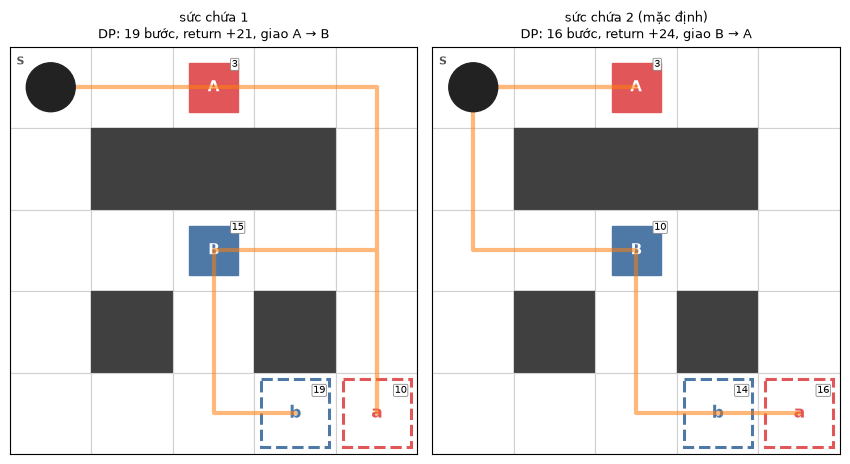

biến thể                           DP: bước  return  thứ tự giao  | Q-learning: bước  return  thứ tự
sức chứa 1                               19     +21  A → B        |               19     +21  A → B ✅
sức chứa 2 (mặc định)                    16     +24  B → A        |               16     +24  B → A ✅

sức chứa 1: lấy kiện A (bước 3) → giao kiện A (bước 10) → lấy kiện B (bước 15) → giao kiện B (bước 19)

sức chứa 2 (mặc định): lấy kiện A (bước 3) → lấy kiện B (bước 10) → giao kiện B (bước 14) → giao kiện A (bước 16)


In [25]:
cfg = MAPS["L1"]
rows_cap = variant_study("L1", [
    ("sức chứa 1", dict(cfg, capacity=1)),
    ("sức chứa 2 (mặc định)", cfg),
], "thi_nghiem_suc_chua.png")

Mang được 2 kiện thì robot lấy cả A lẫn B rồi giao một lượt (16 bước). Chỉ mang được 1 thì phải đi 2 chuyến (19 bước).

## 11. Phân tích trường hợp thất bại / hội tụ chậm

### 11.1 Monte Carlo on-policy (không exploring starts) thất bại ngay cả ở map nhỏ nhất

MC on-policy trên L1: return từ S = -100 (tối ưu 24), giao xong: False, đúng 45% state

Policy tham lam đi từ S:
  robot (0,0) | A: chưa lấy | B: chưa lấy       -> Phải   Q(s,·) = [-107.  -109.3 -107.1 -105.7 -119.  -118.9]
  robot (0,1) | A: chưa lấy | B: chưa lấy       -> Phải   Q(s,·) = [-107.9 -108.4 -111.4 -105.5 -121.9 -118. ]
  robot (0,2) | A: chưa lấy | B: chưa lấy       -> Trái   Q(s,·) = [-103.8 -104.9 -102.7 -103.  -112.  -113.6]
  ↳ quay lại một state đã gặp -> policy tham lam (tất định) sẽ lặp vòng này mãi mãi


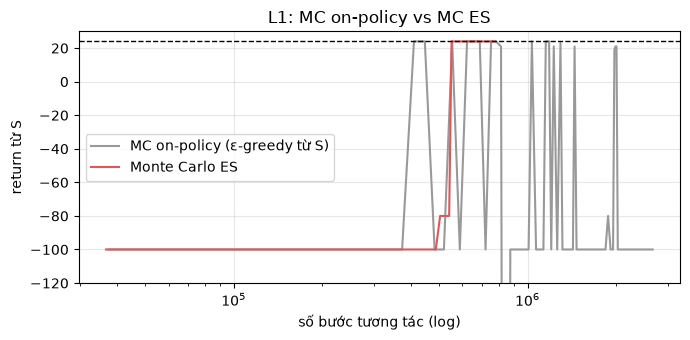

In [26]:
env = ENVS["L1"]
Q_on, h_on = train(env, "mc_on", 30_000 // (4 if QUICK else 1), alpha=0.1, eps_start=1.0, eps_end=0.05,
                   q_init=0.0, seed=0)
ev_on = evaluate(env, Q_on, OPT["L1"])
print(f"MC on-policy trên L1: return từ S = {ev_on['G']:.0f} (tối ưu {OPT['L1']['G']:.0f}), "
      f"giao xong: {ev_on['ok']}, đúng {100 * ev_on['acc']:.0f}% state")
print("\nPolicy tham lam đi từ S:")
s, _ = env.reset()
seen = {s}
for k in range(15):
    a = int(Q_on[s].argmax())
    s2, r, term, trunc, _ = env.step(a)
    print(f"  {env.describe(s):45} -> {ACTION_NAMES[a]:6} Q(s,·) = {np.round(Q_on[s], 1)}")
    if term:
        break
    if s2 in seen:
        print("  ↳ quay lại một state đã gặp -> policy tham lam (tất định) sẽ lặp vòng này mãi mãi")
        break
    seen.add(s2)
    s = s2

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(h_on["eval_steps"], h_on["eval_return"], color="#999", label="MC on-policy (ε-greedy từ S)")
r_es = RESULTS[("L1", "mc")][0]["hist"]
ax.plot(r_es["eval_steps"], r_es["eval_return"], color=ALGO_COLOR["mc"], label="Monte Carlo ES")
ax.axhline(OPT["L1"]["G"], color="k", ls="--", lw=1)
ax.set(xscale="log", ylim=(-120, 30), xlabel="số bước tương tác (log)", ylabel="return từ S", title="L1: MC on-policy vs MC ES")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/that_bai_mc.png", dpi=120); plt.show()

**Vì sao?** MC chỉ cập nhật $Q$ khi **hết episode**. Trong cả episode $Q$ đứng yên, nên nếu policy tham lam tạo thành một vòng (đi qua lại giữa vài ô, hoặc đâm tường / Pickup sai làm robot đứng yên), robot đi vòng đó cho tới khi bị cắt ở `max_steps`. Return của mọi action vì thế đều quanh −100, MC không phân biệt được action tốt và xấu (các giá trị Q in ra ở trên đều nằm trong khoảng −103…−122). Trên đường học, MC on-policy thỉnh thoảng tìm ra lộ trình đúng nhưng **không giữ được**: chỉ cần một episode lặp vòng là $Q$ dọc đường bị kéo về −100. Đi ngẫu nhiên thì hầu như không bao giờ giao xong cả 2 kiện trong 100 bước. MC cần episode **kết thúc thật** để học.

**Cách sửa:** *exploring starts*. Episode bắt đầu ngay cạnh đích (vd. đang mang kiện cuối, đứng cạnh điểm giao) sẽ kết thúc sau vài bước, cho return chính xác. Giá trị đúng sau đó lan ngược dần về S. TD (SARSA, Q-learning) không gặp vấn đề này vì cập nhật $Q$ **ngay sau mỗi bước**: đâm tường một lần là Q của action đó giảm ngay.

### 11.2 Q-learning với $Q_0 = 0$ (không lạc quan): mắc kẹt ở lộ trình trễ deadline

In [27]:
env = ENVS["L3"]
print(f"L3 — tối ưu: return {OPT['L3']['G']:+.0f}, giao {order_text(OPT['L3']['steps'])}\n")
for seed in SEEDS:
    Q0, _ = train(env, "ql", EPISODES["L3"]["ql"], alpha=0.3, eps_start=1.0, eps_end=0.05, q_init=0.0, seed=seed)
    e0 = evaluate(env, Q0, OPT["L3"])
    e1 = RESULTS[("L3", "ql")][SEEDS.index(seed)]
    print(f"seed {seed}: Q0 = 0      -> return {e0['G']:+4.0f}, giao {order_text(e0['steps']):10} | {route_text(e0['steps'])[:95]}")
    print(f"        Q0 = lạc quan -> return {e1['G']:+4.0f}, giao {order_text(e1['steps']):10}")

L3 — tối ưu: return +20, giao C → B → A



seed 0: Q0 = 0      -> return   -5, giao A → B → C  | lấy kiện A (bước 7) → giao kiện A (bước 12) → lấy kiện B (bước 15) → giao kiện B · trễ deadline
        Q0 = lạc quan -> return  +20, giao C → B → A 


seed 1: Q0 = 0      -> return   -4, giao A → B → C  | lấy kiện A (bước 6) → giao kiện A (bước 11) → lấy kiện B (bước 14) → giao kiện B (bước 21) → tr
        Q0 = lạc quan -> return  +20, giao C → B → A 


seed 2: Q0 = 0      -> return   -2, giao A → B → C  | lấy kiện A (bước 4) → giao kiện A (bước 9) → lấy kiện B (bước 12) → giao kiện B (bước 19) → trễ
        Q0 = lạc quan -> return  +20, giao C → B → A 


**Vì sao?** Với $Q_0 = 0$, khi agent đã tìm được lộ trình A → B → C (return dương, khoảng 0), mọi action chưa thử có $Q = 0$ trông **không hấp dẫn hơn** action đã biết. Agent chỉ còn trông vào ε ngẫu nhiên. Muốn khám phá ra “đi thẳng tới C ngay từ đầu” cần một chuỗi dài nhiều bước ngẫu nhiên đúng hướng, gần như không xảy ra. Đây là **tối ưu cục bộ do khám phá kém**. Khởi tạo lạc quan khiến mọi action chưa thử đều trông tốt, nên agent đi thử một cách có hệ thống.

### 11.3 “Đúng trên đường đi” ≠ “đúng ở mọi nơi”

Cho policy tham lam xuất phát từ **mọi** state đạt tới được (không chỉ S) và đếm tỉ lệ giao xong hết trong `max_steps`.

In [28]:
def success_from_all_states(env, pi):
    """Chạy song song policy pi từ mọi state đạt tới được (dùng bảng mô hình để đánh giá cho nhanh)."""
    S = env.reachable_states()
    S = S[~env.is_terminal[S]]
    cur, done = S.copy(), np.zeros(len(S), dtype=bool)
    for _ in range(env.max_steps):
        a = pi[cur]
        done |= env.TERM[cur, a]
        cur = np.where(done, cur, env.NS[cur, a])
    return done.mean()


print(f"{'map':4} {'thuật toán':15} {'từ S':>6} {'đúng % state':>13} {'giao xong từ mọi state':>23}")
for name, env in ENVS.items():
    print(f"{name:4} {'Value Iteration':15} {'✅':>5} {100.0:>12.1f}% {100 * success_from_all_states(env, OPT[name]['pi']):>22.1f}%")
    for algo in ALGO_ORDER:
        r = RESULTS[(name, algo)][0]
        pi = r["Q"].argmax(axis=1)
        print(f"{name:4} {ALGOS[algo][0]:15} {'✅' if r['optimal'] else '❌':>5} {100 * r['acc']:>12.1f}% "
              f"{100 * success_from_all_states(env, pi):>22.1f}%")

map  thuật toán        từ S  đúng % state  giao xong từ mọi state
L1   Value Iteration     ✅        100.0%                  100.0%
L1   Q-learning          ✅         55.6%                   42.5%
L1   SARSA               ❌         81.2%                   78.8%
L1   Monte Carlo ES      ✅        100.0%                  100.0%
L2   Value Iteration     ✅        100.0%                  100.0%
L2   Q-learning          ✅         59.8%                   47.0%
L2   SARSA               ✅         79.5%                   52.1%
L2   Monte Carlo ES      ✅        100.0%                  100.0%
L3   Value Iteration     ✅        100.0%                  100.0%
L3   Q-learning          ✅         76.7%                   94.8%
L3   SARSA               ❌         66.8%                   97.6%
L3   Monte Carlo ES      ✅         99.7%                  100.0%
L4   Value Iteration     ✅        100.0%                  100.0%
L4   Q-learning          ✅         27.4%                    6.9%
L4   SARSA              

- **Q-learning / SARSA** chỉ xuất phát ở S. Chúng học rất nhanh *lộ trình từ S*, nhưng các state ít ghé vẫn giữ $Q_0$ lạc quan nên action ở đó gần như ngẫu nhiên. Đặt robot ở chỗ lạ (thử bằng trò chơi ở mục 12: đi lung tung vài bước rồi bấm 🤖) thì policy có thể đi lòng vòng.
- **Monte Carlo ES** xuất phát ngẫu nhiên nên học được policy đúng ở gần như mọi state, nhưng cần nhiều bước tương tác hơn hẳn.
- **Value Iteration** đúng 100% vì quét mọi state, nhưng nó **cần biết mô hình**.

### 11.4 Tốc độ hội tụ theo kích thước state space

SARSA: chưa hội tụ ở mọi seed trên L1, L3 (không vẽ điểm đó)
Monte Carlo ES: chưa hội tụ ở mọi seed trên L4 (không vẽ điểm đó)


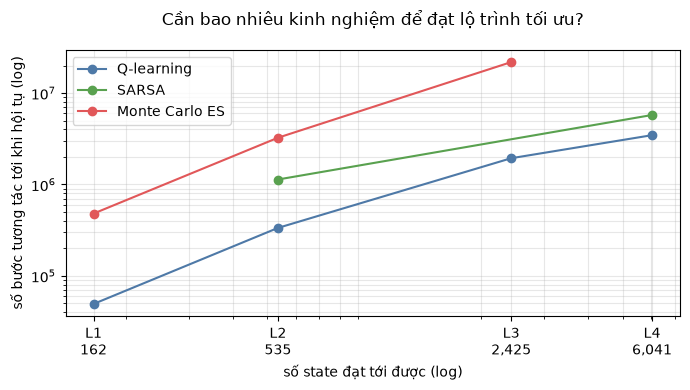

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [len(ENVS[n].reachable_states()) for n in ENVS]
for algo in ALGO_ORDER:
    ys = [next(r for r in SUMMARY if r["map"] == n and r["algo"] == ALGOS[algo][0])["conv_steps"] for n in ENVS]
    xs = [s for s, y in zip(sizes, ys) if y]
    ax.plot(xs, [y for y in ys if y], "o-", color=ALGO_COLOR[algo], label=ALGOS[algo][0])
    missing = [n for n, y in zip(ENVS, ys) if y is None]
    if missing:
        print(f"{ALGOS[algo][0]}: chưa hội tụ ở mọi seed trên {', '.join(missing)} (không vẽ điểm đó)")
ax.set(xscale="log", yscale="log", xlabel="số state đạt tới được (log)",
       ylabel="số bước tương tác tới khi hội tụ (log)")
ax.set_title("Cần bao nhiêu kinh nghiệm để đạt lộ trình tối ưu?", pad=18)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks(sizes)
ax.set_xticklabels([f"{n}\n{s:,}" for n, s in zip(ENVS, sizes)])
ax.legend(); ax.grid(alpha=.3, which="both"); plt.tight_layout()
plt.savefig(f"{OUT}/hoi_tu_theo_kich_thuoc.png", dpi=120); plt.show()

**Nhận xét:**
- Cả 3 thuật toán đều cần nhiều kinh nghiệm hơn khi state space lớn hơn: bảng $Q$ có $|S| \times 6$ ô và ô nào cũng phải được thử.
- Q-learning (off-policy) hội tụ nhanh nhất.
- SARSA (on-policy) chậm hơn và đôi khi dừng ở lộ trình gần tối ưu: nó học giá trị của chính policy ε-greedy, đã tính cả rủi ro từ những bước ngẫu nhiên. Với deadline sát nút ở L3, đi chệch một bước cũng có thể bị trễ.
- Monte Carlo ES cần nhiều bước nhất. Ở L4 (6 nghìn state, 4 kiện) MC chưa chắc hội tụ hết với số episode đã cho. Đây là lý do đề bài chỉ yêu cầu MC trên setting nhỏ.

## 12. Demo một episode bằng policy đã học

In [30]:
def animate_episode(env, pi, title, interval=400, max_frames=90):
    steps, ok = rollout(env, pi)
    states = ([env.s0] + [e["s2"] for e in steps])[:max_frames]
    fig, ax = plt.subplots(figsize=(0.62 * env.W + 1.6, 0.62 * env.H + 1.4))

    def frame(k):
        ax.clear()
        G = sum(e["r"] for e in steps[:k])
        last = f"{ACTION_NAMES[steps[k - 1]['a']]} {steps[k - 1]['r']:+.0f} {steps[k - 1]['event']}" if k else "bắt đầu"
        draw_state(env, states[k], ax, title=f"{title}\nbước {k}/{len(steps)} · return {G:+.0f} · {last}")

    anim = animation.FuncAnimation(fig, frame, frames=len(states), interval=interval)
    plt.close(fig)
    return anim, steps


for name, algo in [("L4", "ql"), ("L3", "ql")]:
    pi = RESULTS[(name, algo)][0]["Q"].argmax(axis=1)
    anim, steps = animate_episode(ENVS[name], pi, f"{name} · {ALGOS[algo][0]}")
    anim.save(f"{OUT}/demo_{name}.gif", writer=animation.PillowWriter(fps=3))
    print(f"{name}: {len(steps)} bước, return {sum(e['r'] for e in steps):+.0f} | {route_text(steps)}")
    display(HTML(anim.to_jshtml()))

L4: 40 bước, return +40 | lấy kiện A (bước 4) → kích hoạt ô tăng tải (bước 7) → lấy kiện B (bước 9) → giao kiện A (bước 15) → giao kiện B (bước 17) → lấy kiện C (bước 19) → giao kiện C (bước 24) → lấy kiện D (bước 28) → giao kiện D (bước 40)


L3: 40 bước, return +20 | lấy kiện C (bước 11) → giao kiện C (bước 19) → lấy kiện B (bước 21) → giao kiện B (bước 28) → lấy kiện A (bước 35) → giao kiện A (bước 40)


### 12.1 🎮 Chơi cùng AI

Chọn map và policy ở ô **AI**. Bạn có thể tự đi vài bước rồi bấm **🤖 AI 1 bước** / **🤖 AI chạy hết** để xem AI xử lý tiếp từ chỗ đó.

In [ ]:
POLICIES = {name: {"Value Iteration (tối ưu)": OPT[name]["pi"],
                   **{ALGOS[a][0]: RESULTS[(name, a)][0]["Q"].argmax(axis=1) for a in ALGO_ORDER}}
            for name in ENVS}
if widgets is not None:
    game_ai = DeliveryGame("L4", policies=POLICIES)
    display(game_ai.ui)
else:
    print("Không có ipywidgets -> dùng play_text('L4')")

## 13. Lưu kết quả

Mọi file nằm trong thư mục `ket_qua/` (cấu hình map, bảng Q của seed đầu, hình, bảng tổng hợp) và được nén thành `ket_qua.zip`. Trên Colab, ô dưới sẽ tự tải file zip về máy.

In [32]:
for (name, algo), runs in RESULTS.items():
    np.savez_compressed(f"{OUT}/Q_{name}_{algo}.npz", Q=runs[0]["Q"], eval_ep=runs[0]["hist"]["eval_ep"],
                        eval_return=runs[0]["hist"]["eval_return"])
for name in ENVS:
    np.savez_compressed(f"{OUT}/V_star_{name}.npz", V=OPT[name]["V"], pi=OPT[name]["pi"])
with open(f"{OUT}/tong_hop.json", "w", encoding="utf-8") as f:
    json.dump(dict(state_space=STATE_TABLE, training=SUMMARY, episodes=EPISODES, hyper=HYPER, seeds=SEEDS,
                   optimal={n: dict(steps=OPT[n]["n"], G=OPT[n]["G"], route=route_text(OPT[n]["steps"]))
                            for n in ENVS}), f, ensure_ascii=False, indent=1)
shutil.make_archive("ket_qua", "zip", OUT)
print(sorted(os.listdir(OUT)))
if IN_COLAB:
    from google.colab import files
    files.download("ket_qua.zip")

['Q_L1_mc.npz', 'Q_L1_ql.npz', 'Q_L1_sarsa.npz', 'Q_L2_mc.npz', 'Q_L2_ql.npz', 'Q_L2_sarsa.npz', 'Q_L3_mc.npz', 'Q_L3_ql.npz', 'Q_L3_sarsa.npz', 'Q_L4_mc.npz', 'Q_L4_ql.npz', 'Q_L4_sarsa.npz', 'V_star_L1.npz', 'V_star_L2.npz', 'V_star_L3.npz', 'V_star_L4.npz', 'configs', 'demo_L3.gif', 'demo_L4.gif', 'dp_hoi_tu.png', 'duong_hoc.png', 'hoi_tu_theo_kich_thuoc.png', 'maps.png', 'policy_L2_ql.png', 'policy_L3_mc.png', 'policy_L4_ql.png', 'that_bai_mc.png', 'thi_nghiem_deadline.png', 'thi_nghiem_suc_chua.png', 'thi_nghiem_tang_tai.png', 'thi_nghiem_uu_tien.png', 'tong_hop.json']


## 14. Tóm tắt và gợi ý trình bày

**Mô hình.** State = (hàng, cột, trạng thái từng kiện ∈ {chưa lấy, đang mang, đã giao}, đồng hồ deadline $t$, trạng thái tăng tải $b$), mã hóa thành một số nguyên bằng hệ cơ số hỗn hợp; trạng thái kiện là một số hệ cơ số 3. $|A| = 6$. $t$ và $b$ được thêm vào để giữ tính Markov.

**Giải thích nhanh từng thuật toán (mỗi cái một câu):**
- **Policy Evaluation:** lặp $V(s) \leftarrow R + \gamma V(s')$ với action của policy cố định cho tới khi $V$ không đổi.
- **Policy Iteration:** đánh giá policy → chọn action tham lam theo $V$ vừa tính → lặp tới khi policy không đổi.
- **Value Iteration:** lặp $V(s) \leftarrow \max_a [R + \gamma V(s')]$; ít tính toán hơn PI mỗi vòng, cho cùng $V^*$.
- **Monte Carlo ES:** chơi hết episode từ (state, action) ngẫu nhiên, lấy return thật $G_t$ làm mục tiêu cho $Q$.
- **SARSA:** sau mỗi bước, kéo $Q(s,a)$ về $r + \gamma Q(s', a')$ với $a'$ là action **sẽ đi thật**.
- **Q-learning:** sau mỗi bước, kéo $Q(s,a)$ về $r + \gamma \max_{a'} Q(s', a')$, tức học policy tối ưu dù đang đi ε-greedy.

**Kết quả chính** (xem bảng mục 8.2):
1. DP (PI và VI) cho cùng $V^*$ trên cả 4 map. Đây là đáp án chuẩn.
2. Q-learning đạt lộ trình tối ưu trên cả 4 map, ở mọi seed, với ít kinh nghiệm nhất.
3. SARSA tối ưu ở L2, L4; ở L1, L3 nó dừng ở lộ trình dài hơn 1–3 bước, vì nó học giá trị của chính policy ε-greedy.
4. Monte Carlo cần exploring starts mới học được. Nó học đúng gần như **mọi** state (L1–L3) nhưng tốn bước tương tác gấp ~10 lần Q-learning. Ở L4 (state space lớn nhất), 300 nghìn episode vẫn chưa đủ để tìm ra lộ trình tối ưu.
5. Thay reward/tham số môi trường (mục 10) làm policy đổi đúng như trực giác: phạt trễ → lấy C trước; đơn ưu tiên → giao A trước; có ô tăng tải → gộp 2 kiện một chuyến; sức chứa 2 → lấy cả 2 rồi mới giao.

**Câu hỏi hay gặp:**
- *Vì sao không đưa `steps` (số bước đã đi) vào state?* Vì `max_steps` chỉ là giới hạn khi huấn luyện, không phải luật của bài toán. Riêng đồng hồ deadline thì là luật, nên $t$ phải nằm trong state.
- *Vì sao $|S|$ lớn mà số state đạt tới ít hơn nhiều?* Mã hóa tính cả ô tường, tổ hợp vô lý (mang 2 kiện khi sức chứa 1), thời điểm không thể có (ở xa S khi $t$ còn nhỏ)…
- *Tăng tải "một chuyến" nghĩa là gì?* Từ lúc bước vào ô T tới lần giao hàng đầu tiên sau đó; sau lần giao đó sức chứa trở về 1.